In [7]:
import duckdb as db
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd


In [23]:
db.sql("select reason, count(*) from read_parquet('C:/MLAR_DATA/for_model/T0001/*.parquet') group by reason order by reason desc")

┌───────────────────────────────────────────────────────────────────────────────────────────────────────┬──────────────┐
│                                                reason                                                 │ count_star() │
│                                                varchar                                                │    int64     │
├───────────────────────────────────────────────────────────────────────────────────────────────────────┼──────────────┤
│ used retain                                                                                           │            4 │
│ used for HCP, refer to 39703                                                                          │            2 │
│ updating results from run on 17Aug23 as results from 15Aug23 were invalidated                         │            2 │
│ updating results as prior values from 15Aug23 were deemed invalid. these values are from the rereun…  │            2 │
│ updating attachment due to run

In [24]:
df = db.sql("select * from read_parquet('C:/MLAR_DATA/for_model/T0001/*.parquet') ").to_df()

In [ ]:
df.columns.values

In [ ]:
### Missing Data

missing_percentage_by_customer = df.groupby('customer').apply(lambda x: x.isnull().mean() * 100)

# Print the result
print(missing_percentage_by_customer)



In [ ]:
## Store the missing values to put into excel for easy review

missing_percentage_by_customer.to_csv('missing_data.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2047665 entries, 0 to 2047664
Data columns (total 99 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   IN_SPEC_norm              object        
 1   REPLICATE_COUNT_norm      object        
 2   OPTIONAL_norm             object        
 3   NUMERIC_ENTRY_norm        object        
 4   DATE_REVIEWED_norm        object        
 5   PARENT_TEST_norm          object        
 6   ORIGINAL_SAMPLE_norm      object        
 7   SIGNED_norm               object        
 8   FORMATTED_ENTRY_norm      object        
 9   DATE_RECEIVED_norm        object        
 10  LOGIN_BY_norm             object        
 11  BATCH_ORIGINAL_TEST_norm  object        
 12  RESULT_NUMBER_norm        object        
 13  RE_SAMPLE_norm            object        
 14  LIST_KEY_norm             object        
 15  ALIQUOTED_TO_norm         object        
 16  STAGE_norm                object        
 17  BATCH_no

In [ ]:
average_values = df.groupby('customer')['audit_count'].median()

# Plot the bar chart
average_values.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Averag Audit Count')
plt.title('Average Audit Count by Customer')

# Show the plot
plt.show()

In [ ]:
average_values = df.groupby('customer')['seconds_since_start'].mean()

# Plot the bar chart
average_values.plot(kind='bar', color='skyblue', edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Average Second Since Start')
plt.title('Average Seconds Since Start by Customer')

# Show the plot
plt.show()

In [ ]:
group_counts = df.groupby(['customer', 'STATUS_norm']).size().unstack()
group_percentages = group_counts.div(group_counts.sum(axis=1), axis=0) * 100
ax = group_percentages.plot(kind='bar', stacked=True, edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Percent')
plt.title('Status of Sample at Event')

ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

# Show the plot
plt.show()


In [ ]:
group_counts = df.groupby(['customer', 'OLD_STATUS_norm']).size().unstack()
group_percentages = group_counts.div(group_counts.sum(axis=1), axis=0) * 100
ax = group_percentages.plot(kind='bar', stacked=True, edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Percent')
plt.title('Old Status of Sample at Event')

ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

# Show the plot
plt.show()

In [ ]:
df['status_no_change'] = np.where(df["STATUS_norm"] == df['OLD_STATUS_norm'],"Yes", "No")

In [ ]:
group_counts = df.groupby(['customer', 'status_no_change']).size().unstack()
group_percentages = group_counts.div(group_counts.sum(axis=1), axis=0) * 100
ax = group_percentages.plot(kind='bar', stacked=True, edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Percent')
plt.title('No Change to Status of Sample at Event')

ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

# Show the plot
plt.show()

In [ ]:
group_counts = df.groupby(['customer', 'audit_action']).size().unstack()
group_percentages = group_counts.div(group_counts.sum(axis=1), axis=0) * 100
ax = group_percentages.plot(kind='bar', stacked=True, edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Percent')
plt.title('Audit Action of Event by Customer')

ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

# Show the plot
plt.show()

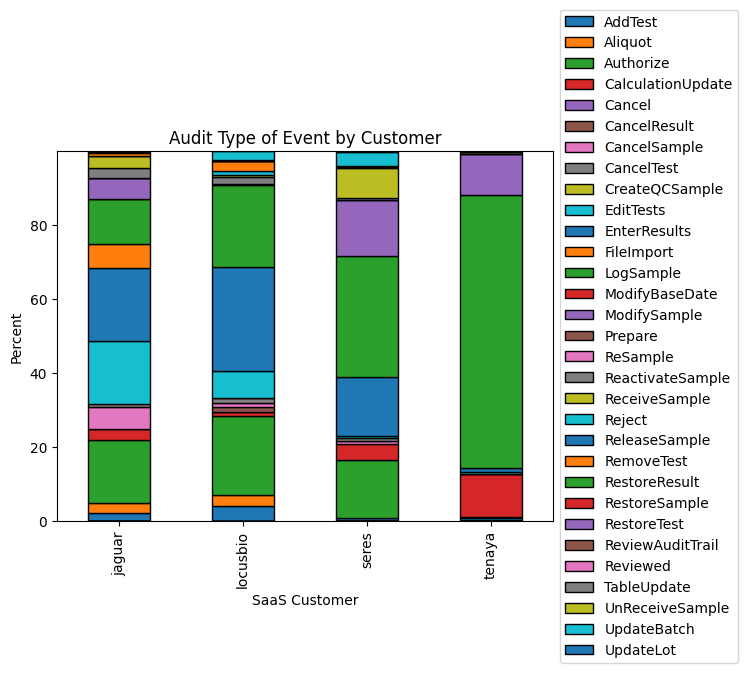

In [5]:
group_counts = df.groupby(['customer', 'audit_type']).size().unstack()
group_percentages = group_counts.div(group_counts.sum(axis=1), axis=0) * 100
ax = group_percentages.plot(kind='bar', stacked=True, edgecolor='black')

# Add labels and title
plt.xlabel('SaaS Customer')
plt.ylabel('Percent')
plt.title('Audit Type of Event by Customer')

ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

# Show the plot
plt.show()

In [ ]:
print("\nSummary Statistics:")
print(df.describe())

In [12]:
object_columns = df.select_dtypes(include=['object']).columns

# Convert object columns to floats
for col in object_columns:
    try: 
        df[col] = pd.to_numeric(df[col])
    except:
        print('DAta Type Change Failed')


# Check the updated DataFrame
print(df.info())

DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change

In [15]:
object_columns = df.select_dtypes(include=['object']).columns

# Convert object columns to floats
for col in object_columns:
    try: 
        df[col] = pd.to_datetime(df[col])
    except:
        print('DAta Type Change Failed')


# Check the updated DataFrame
print(df.info())

C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])


DAta Type Change Failed
DAta Type Change Failed


C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])


DAta Type Change Failed
DAta Type Change Failed


C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each ele

DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed


... (15 outputs left out)

DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed


C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each ele

DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
DAta Type Change Failed
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2047665 entries, 0 to 2047664
Data columns (total 99 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   IN_SPEC_norm              object        
 1   REPLICATE_COUNT_norm      float64       
 2   OPTIONAL_norm             object        
 3   NUMERIC_ENTRY_norm        float64       
 4   DATE_REVIEWED_norm        datetime64[ns]
 5   PARENT_TEST_norm          float64       
 6   ORIGINAL_SAMPLE_norm      float64       
 7   SIGNED_norm               object        
 8   FORMATTED_ENTRY_norm      object        
 9   DATE_RECEIVED_norm        datetime64[ns]
 10  LOGIN_BY_norm             object        
 11  BATCH_ORIGINAL_TEST_norm  float64       
 12

C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col])
C:\Users\dan.larson\AppData\Local\Temp\5\ipykernel_15288\366792752.py:6: UserWarning: Could not infer format, so each ele

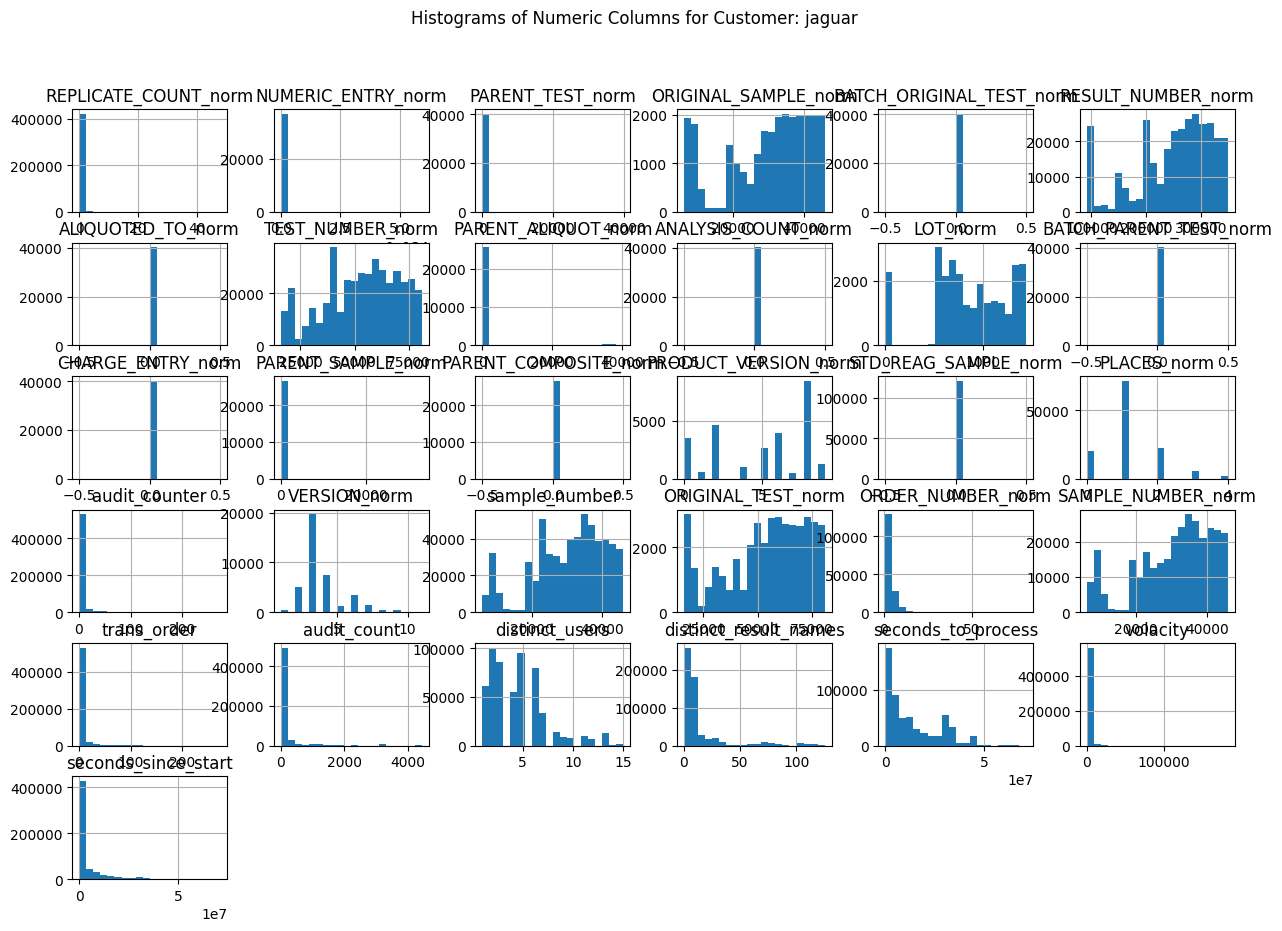

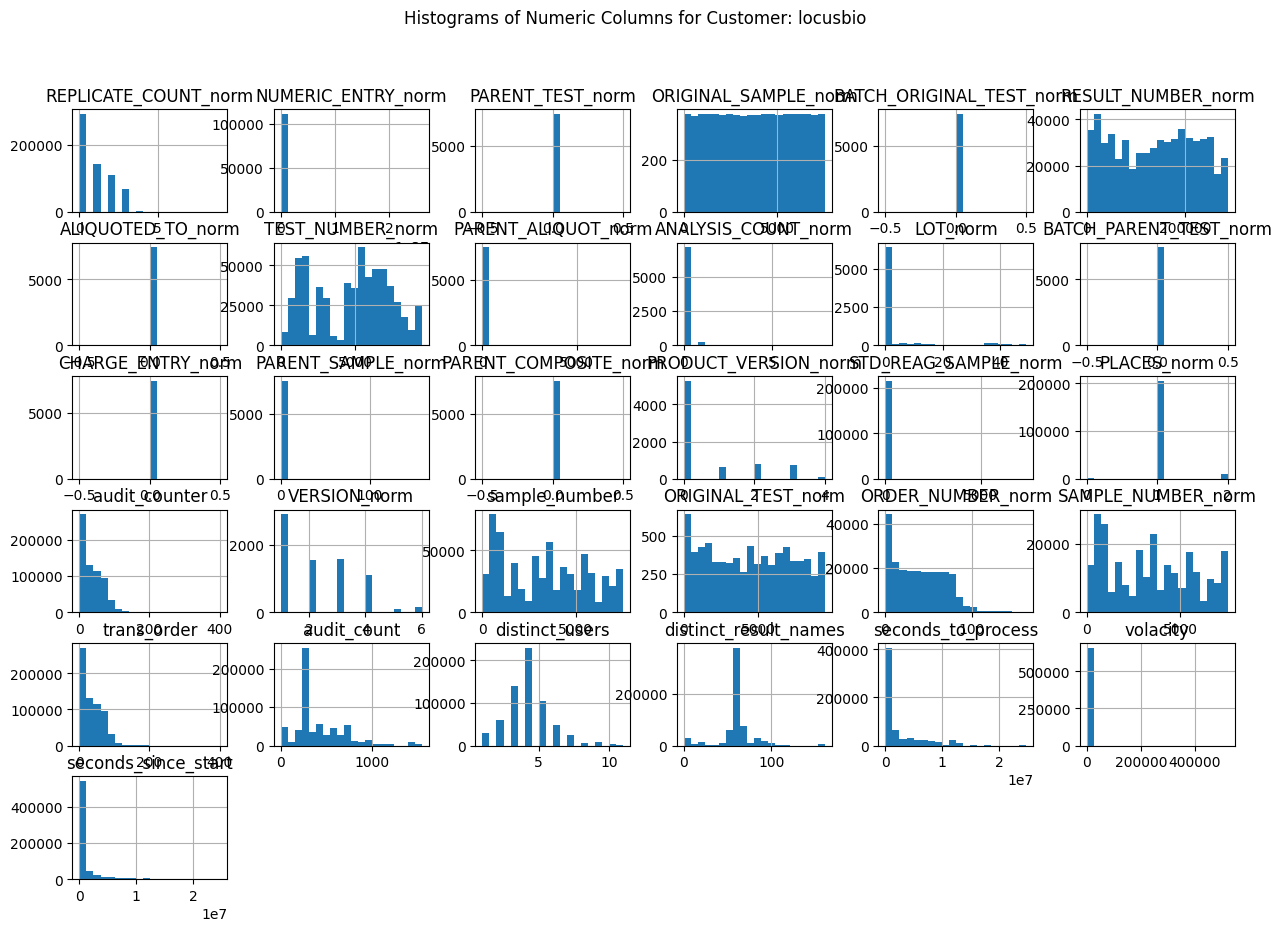

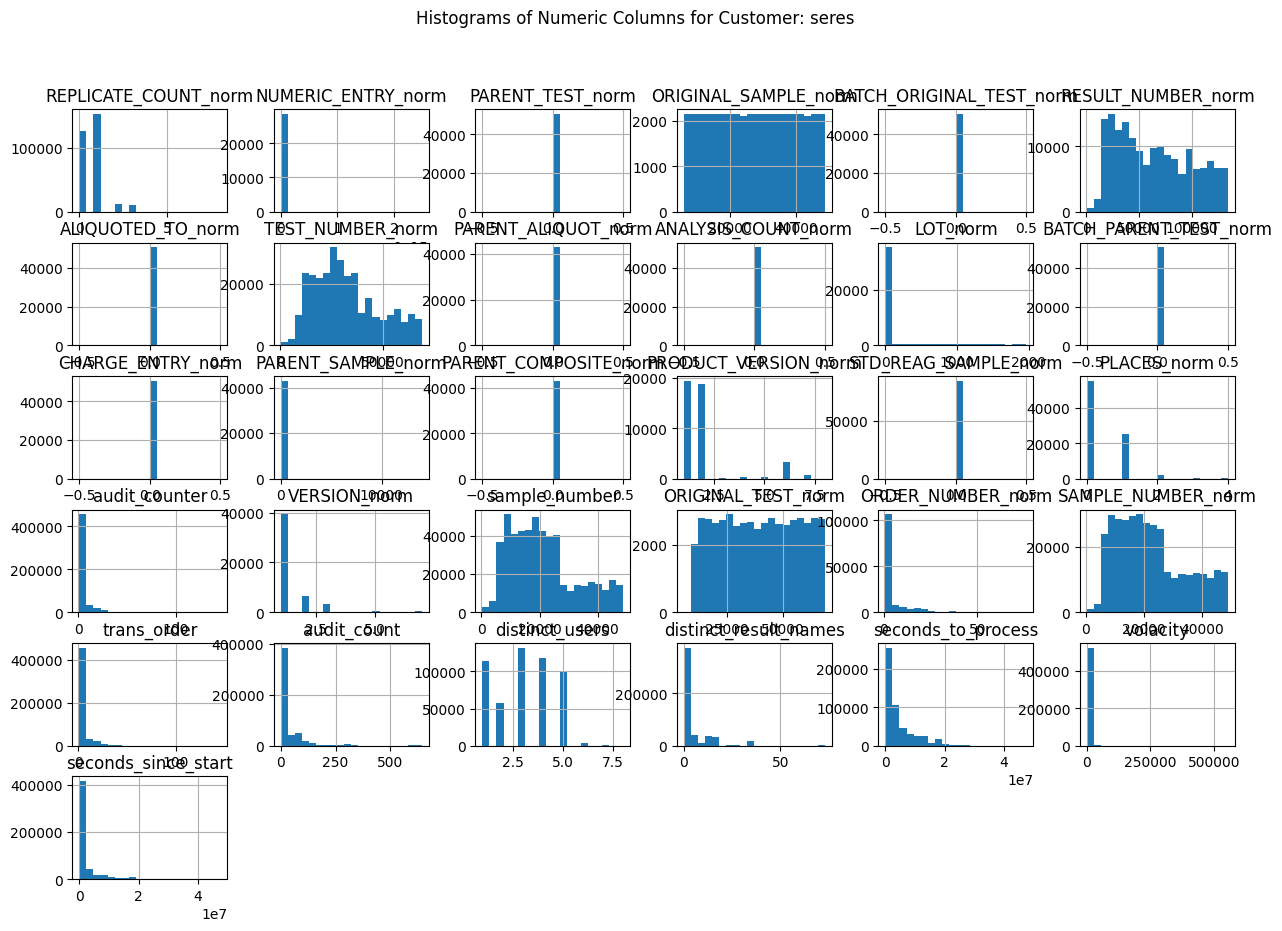

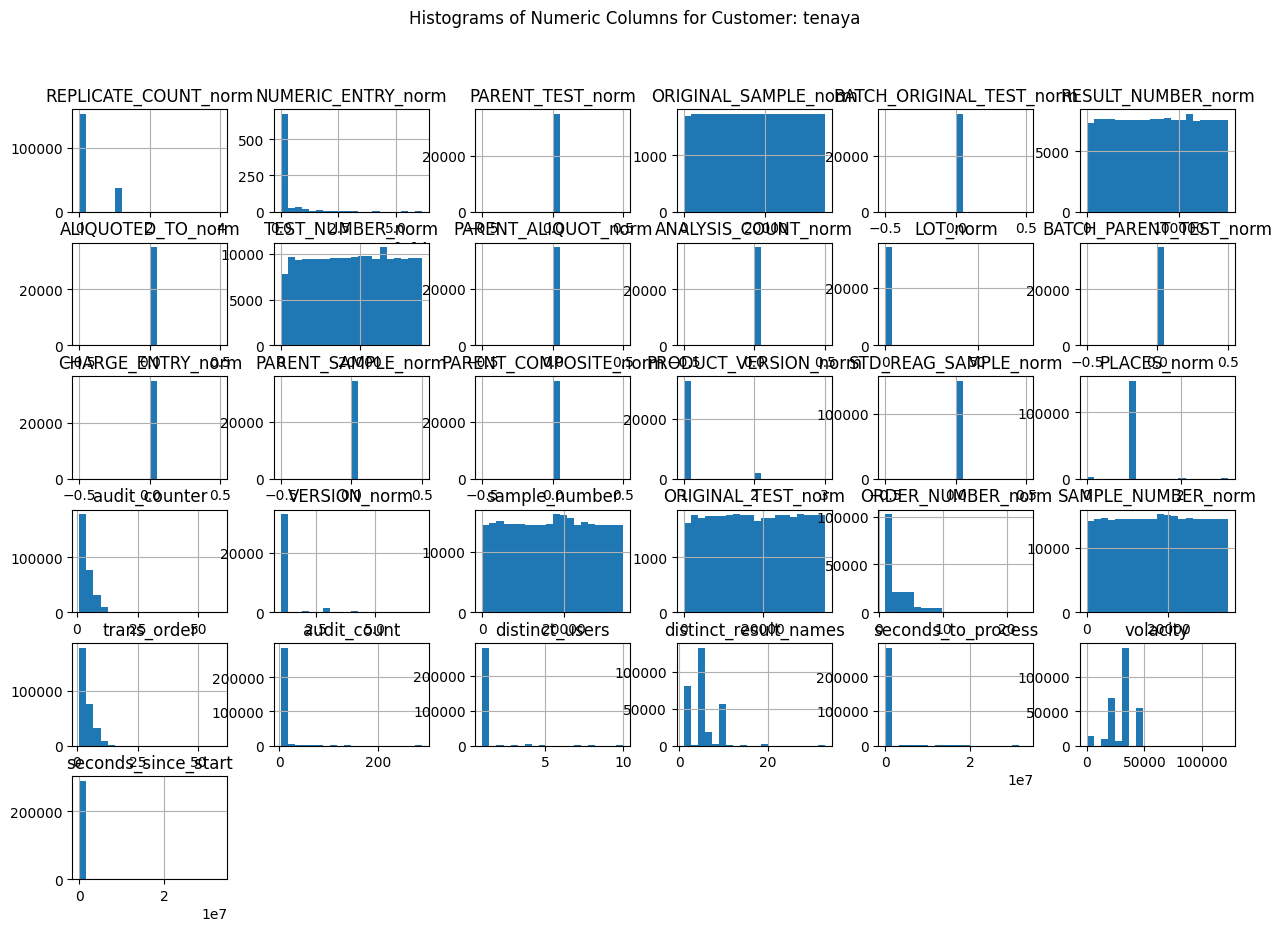

In [13]:
# Plot distribution of numeric columns
unique_customers = df['customer'].unique()

# Loop through each customer and create separate histograms
for customer in unique_customers:
    # Filter the DataFrame for the specific customer
    customer_df = df[df['customer'] == customer]

    # Plot distribution of numeric columns for the current customer
    numeric_cols = customer_df.select_dtypes(include=['float64', 'int64']).columns
    customer_df[numeric_cols].hist(bins=20, figsize=(15, 10))
    plt.suptitle(f"Histograms of Numeric Columns for Customer: {customer}")
    plt.show()


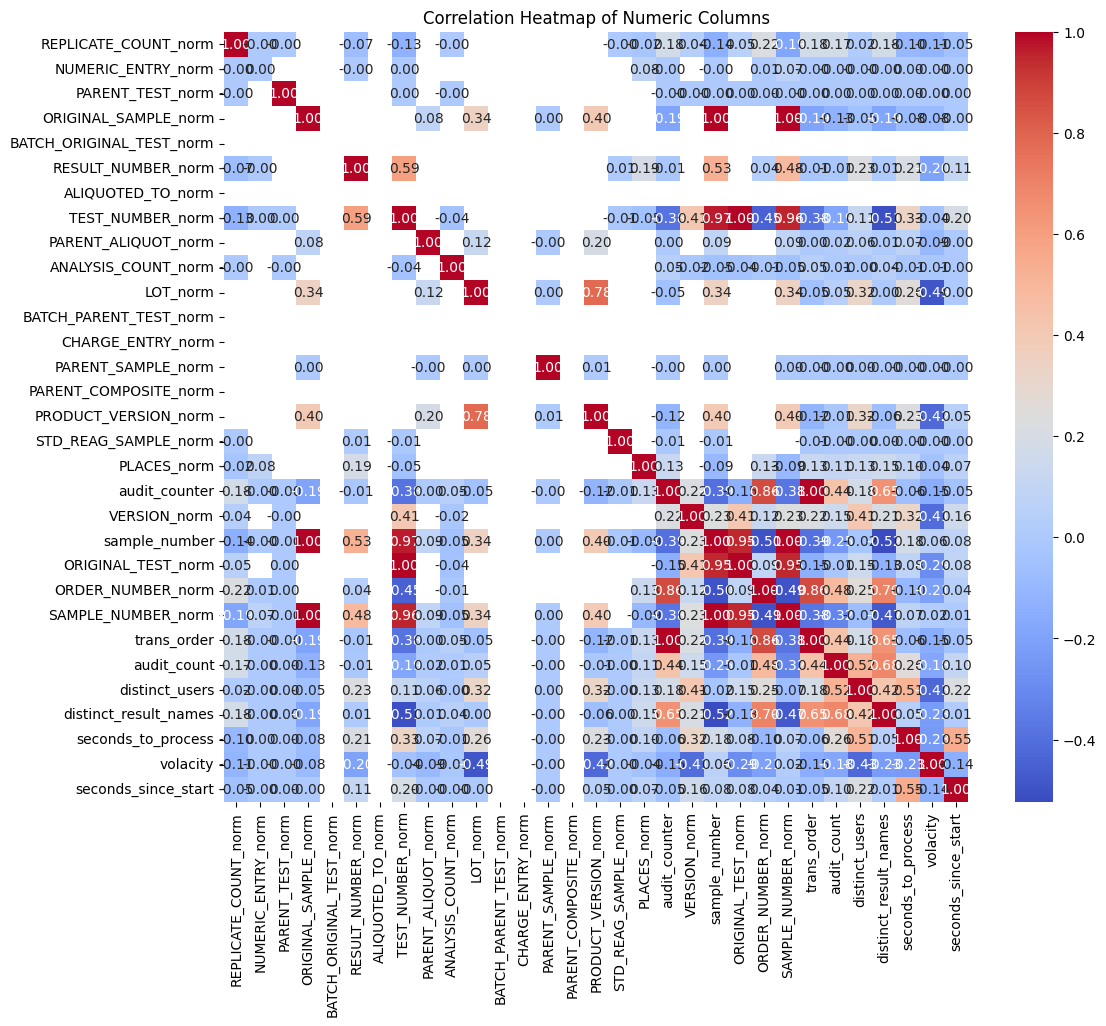

In [14]:
# Plot correlation heatmap of numeric columns
correlation_matrix = df[numeric_cols].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numeric Columns")
plt.show()


In [ ]:
unique_customers = df['customer'].unique()

# Loop through each customer and create separate histograms
for customer in unique_customers:
    # Filter the DataFrame for the specific customer
    customer_df = df[df['customer'] == customer]

    # Plot distribution of numeric columns for the current customer
    numeric_cols = customer_df.select_dtypes(include=['float64', 'int64']).columns

    correlation_matrix = customer_df[numeric_cols].corr()
    plt.figure(figsize=(12, 10))
    sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
    plt.suptitle(f"Histograms of Numeric Columns for Customer: {customer}")
    plt.show()

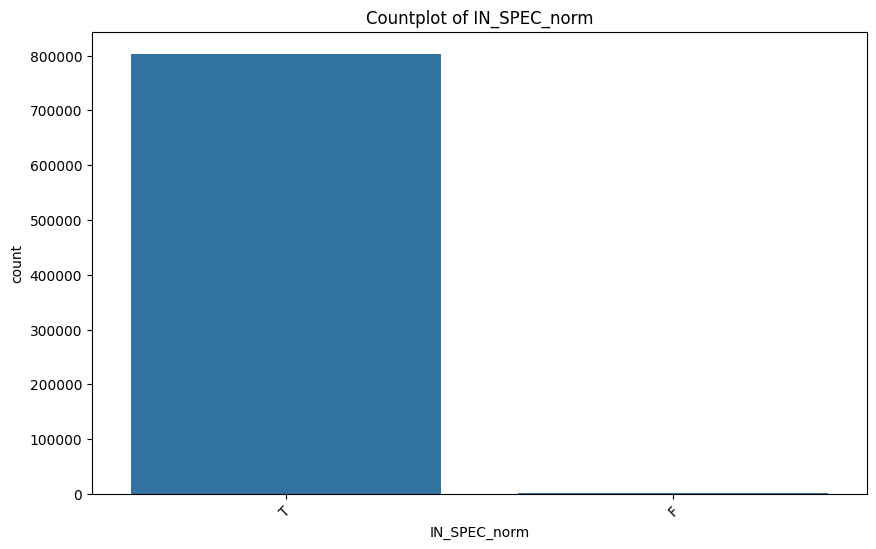

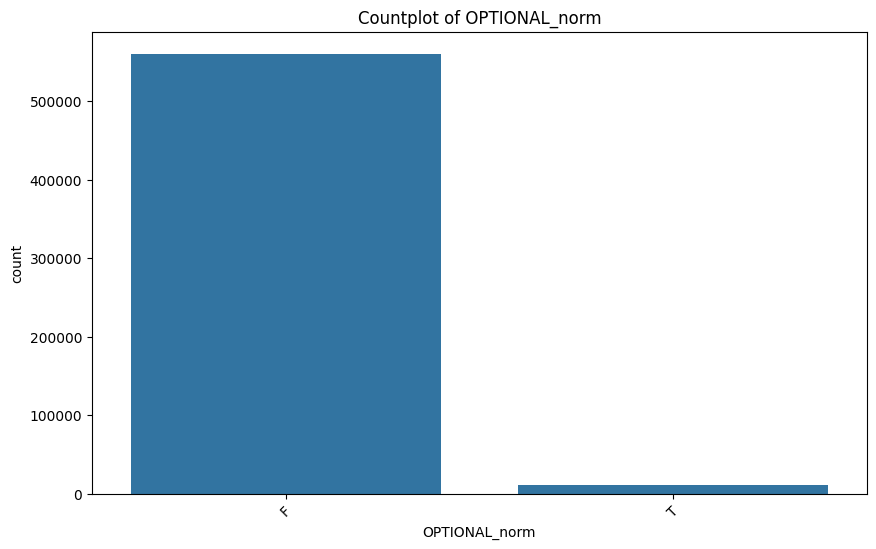

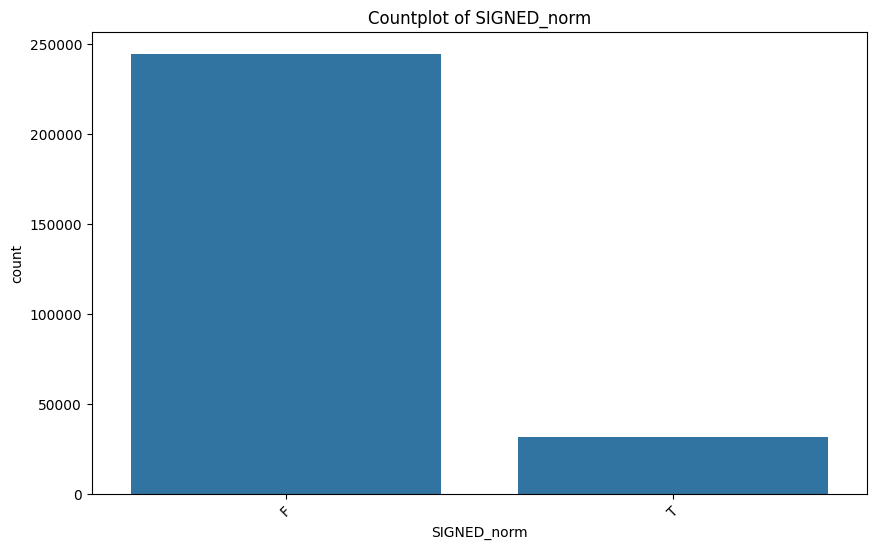

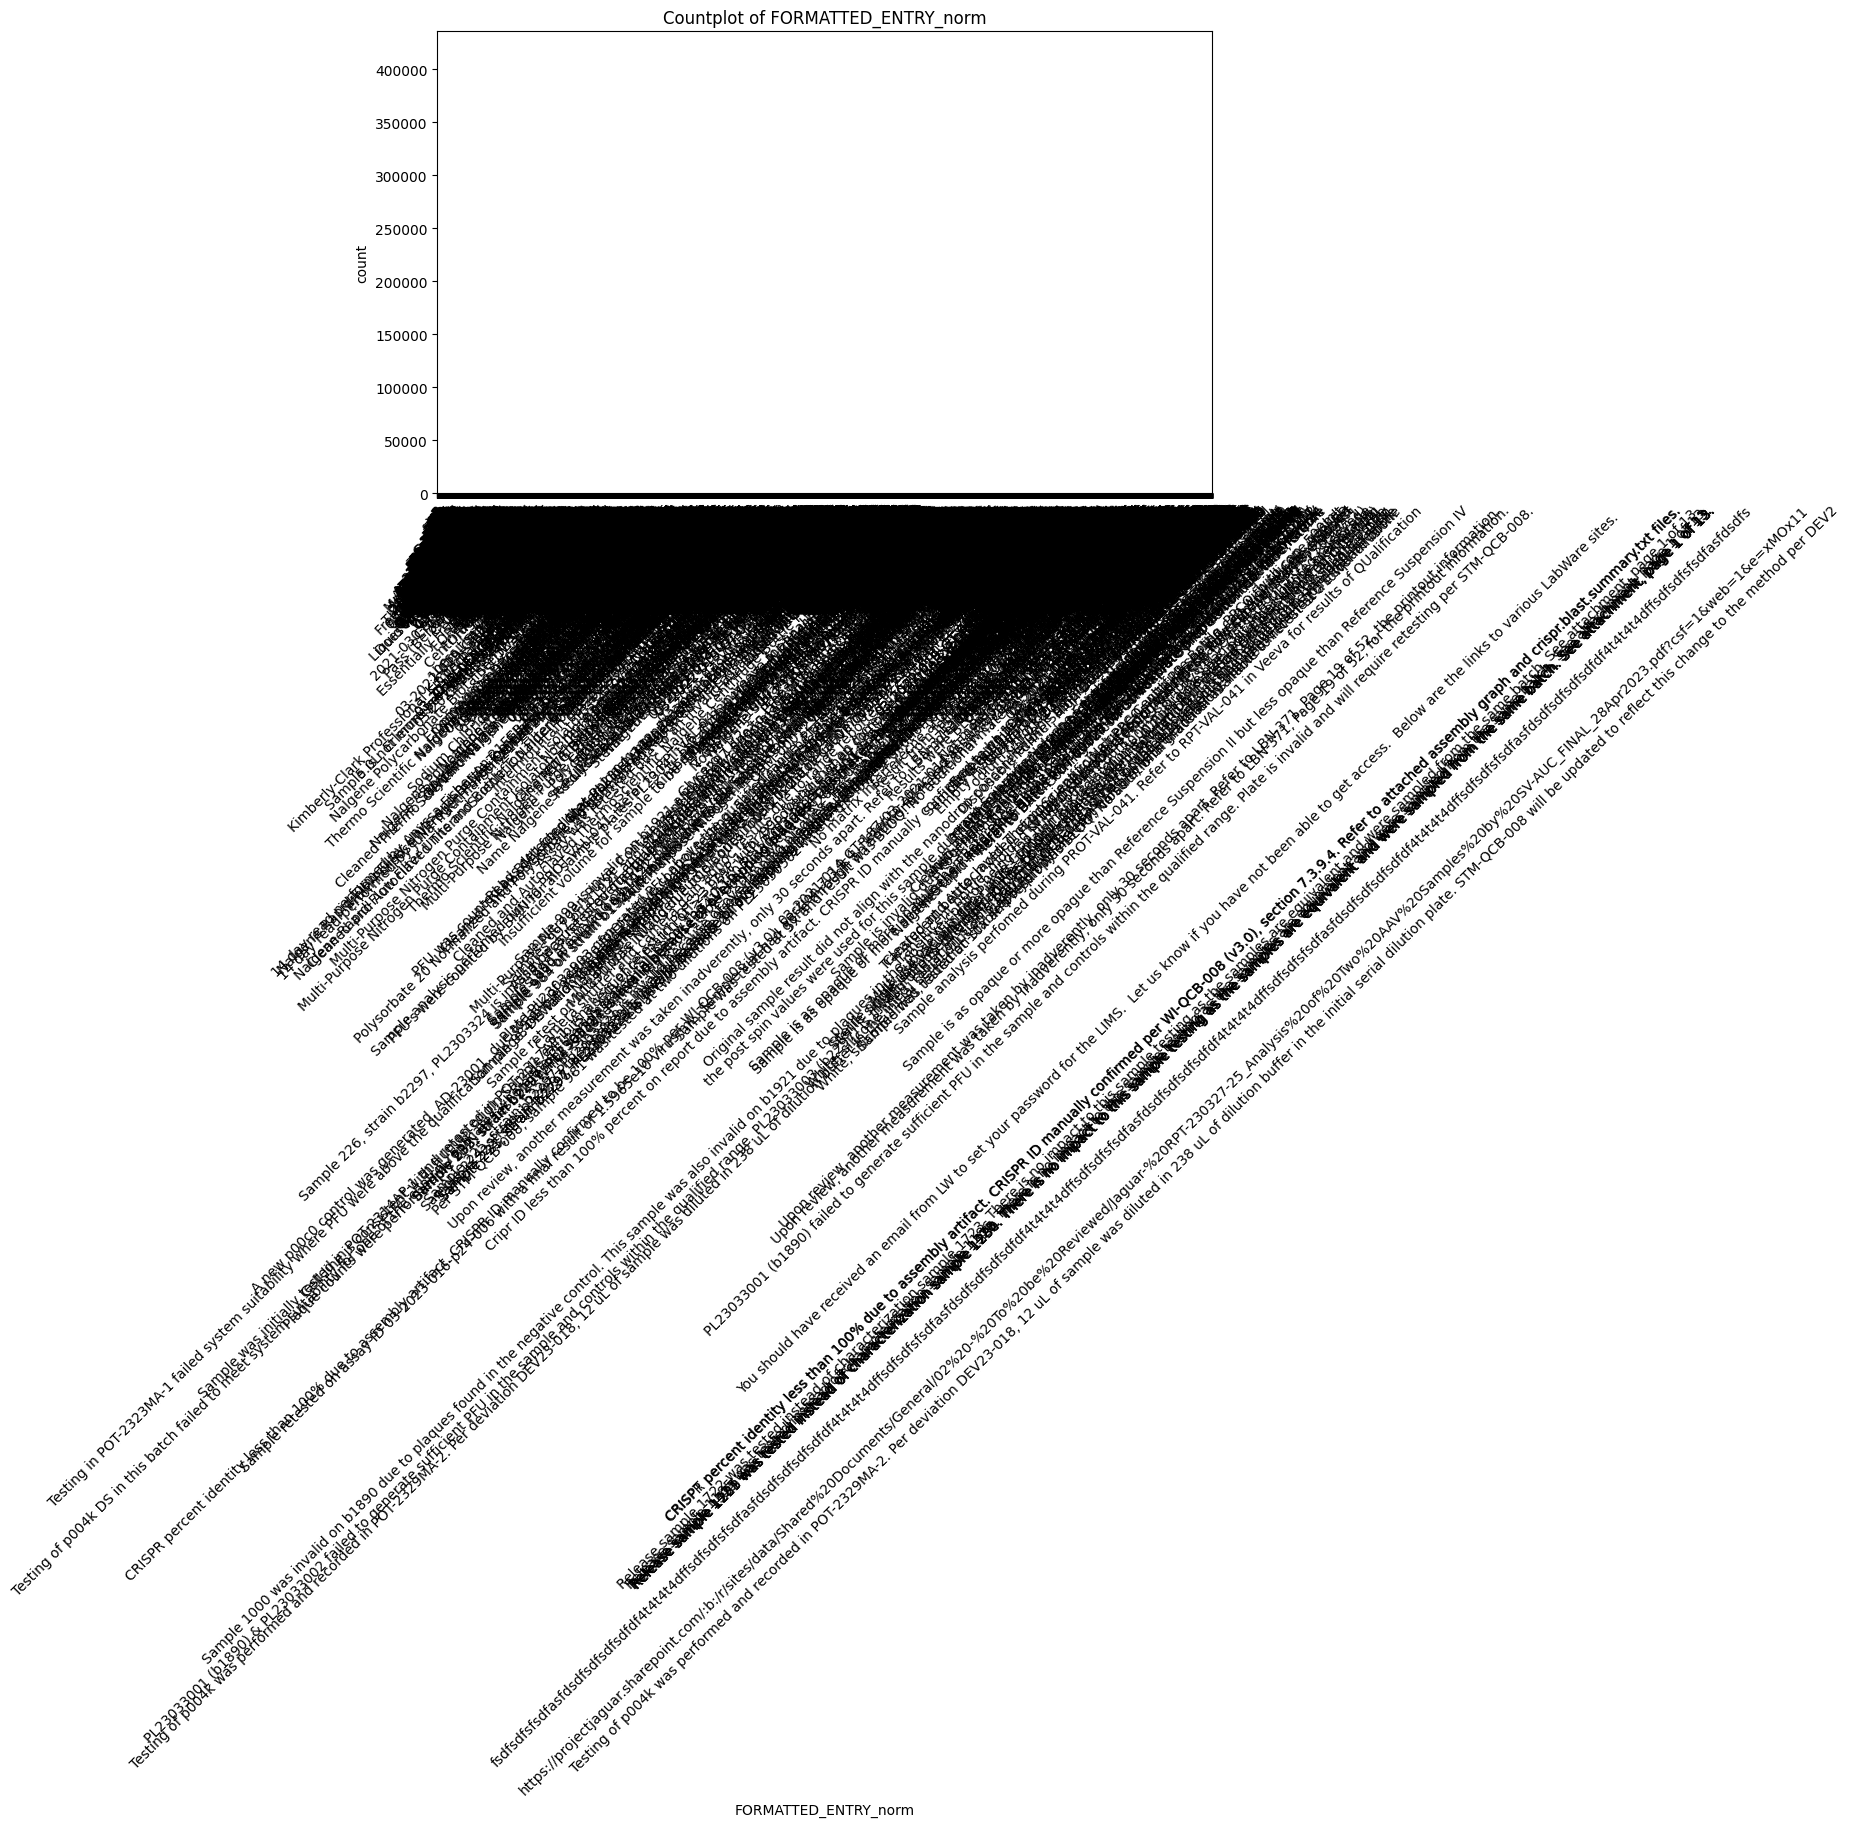

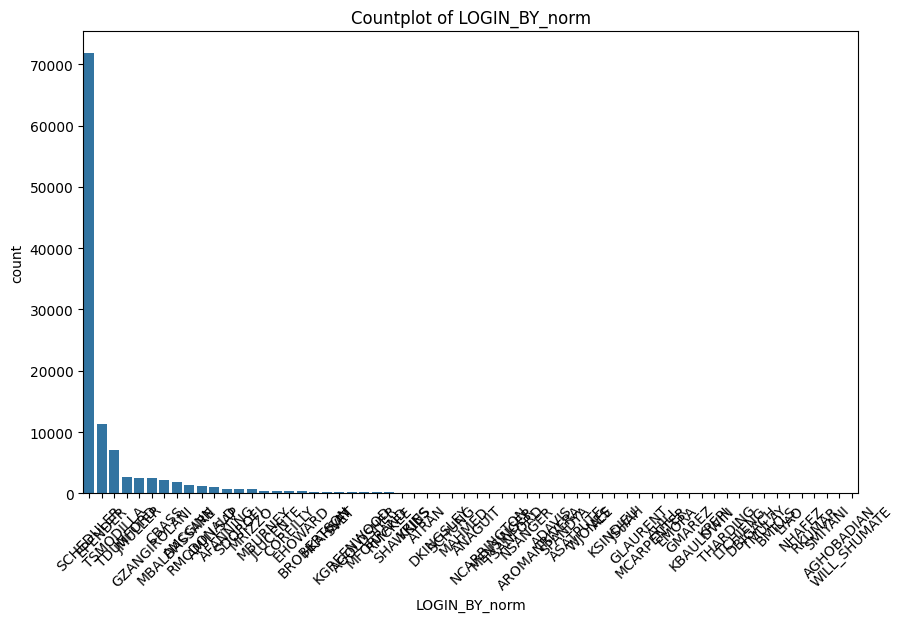

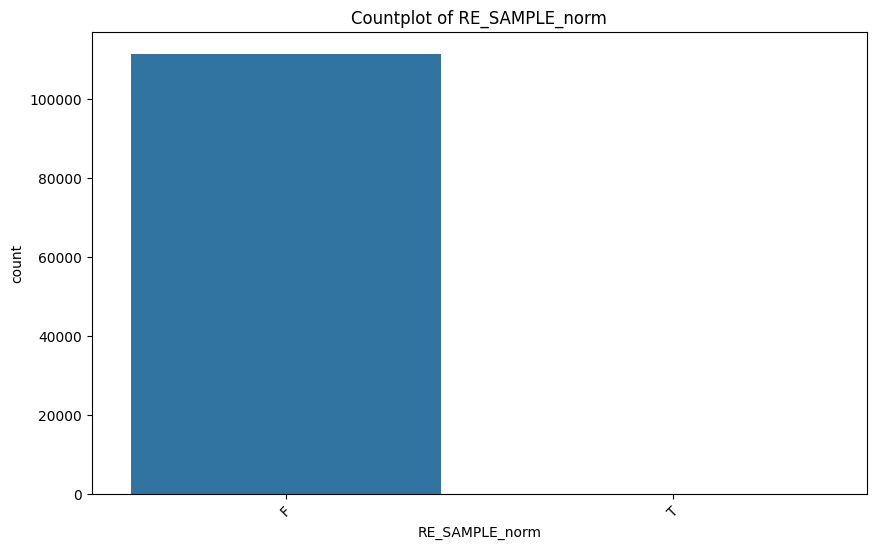

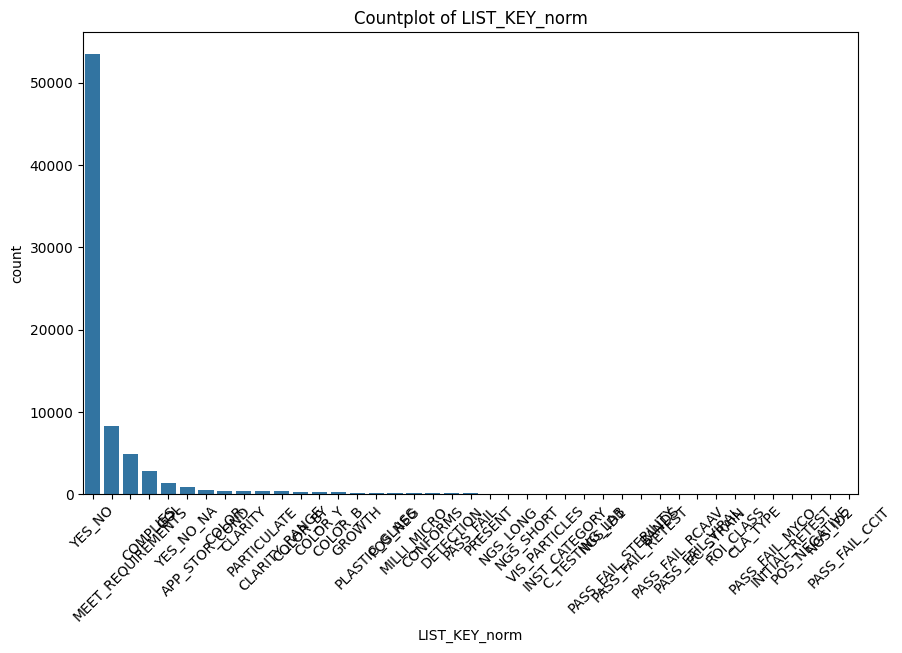

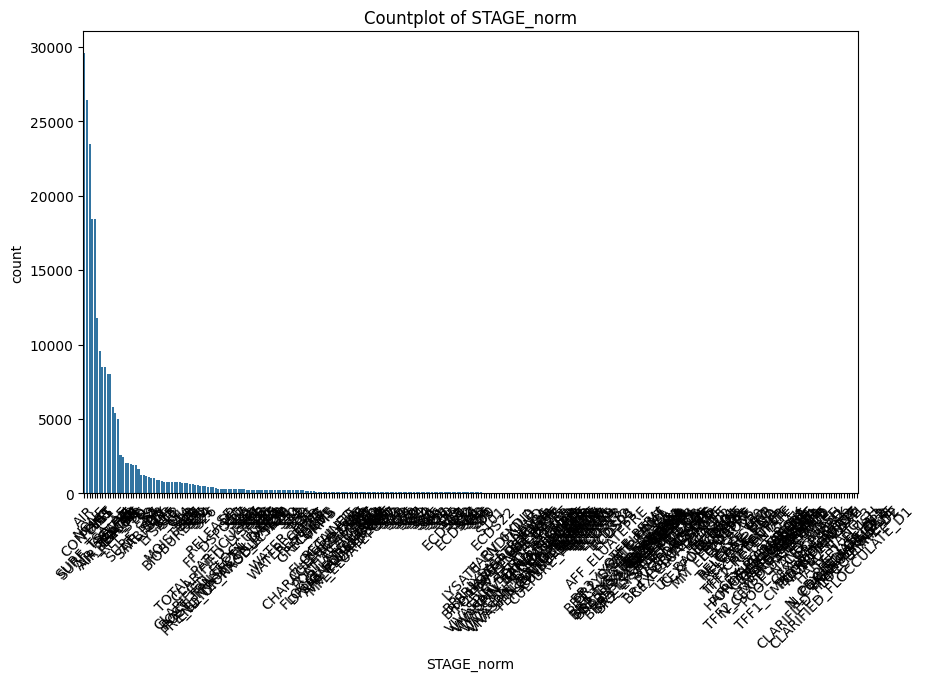

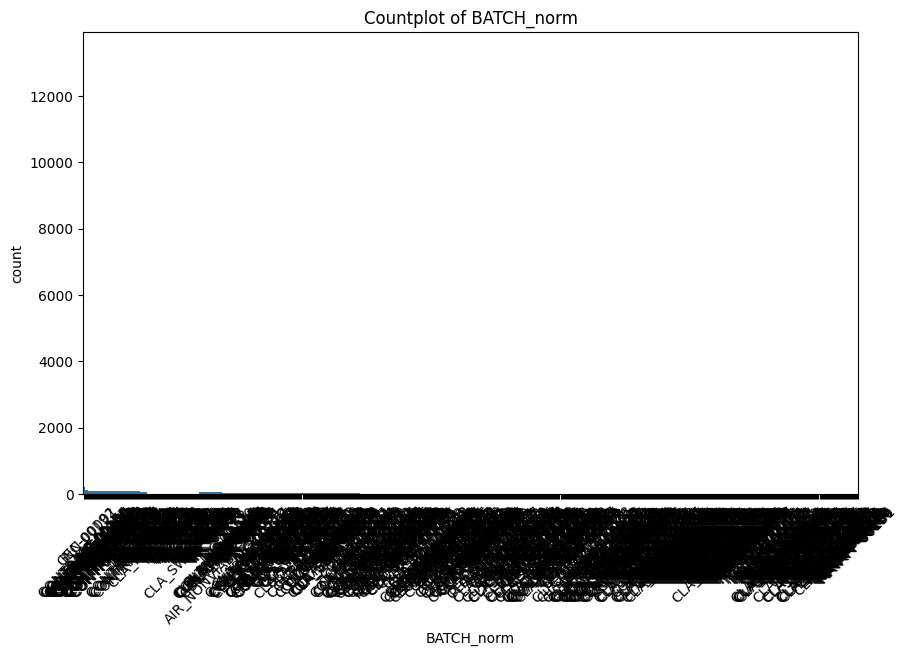

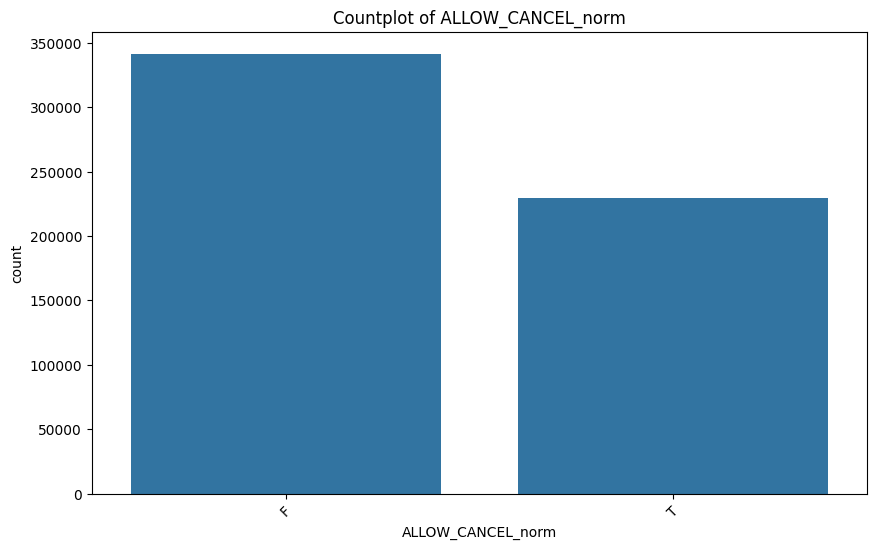

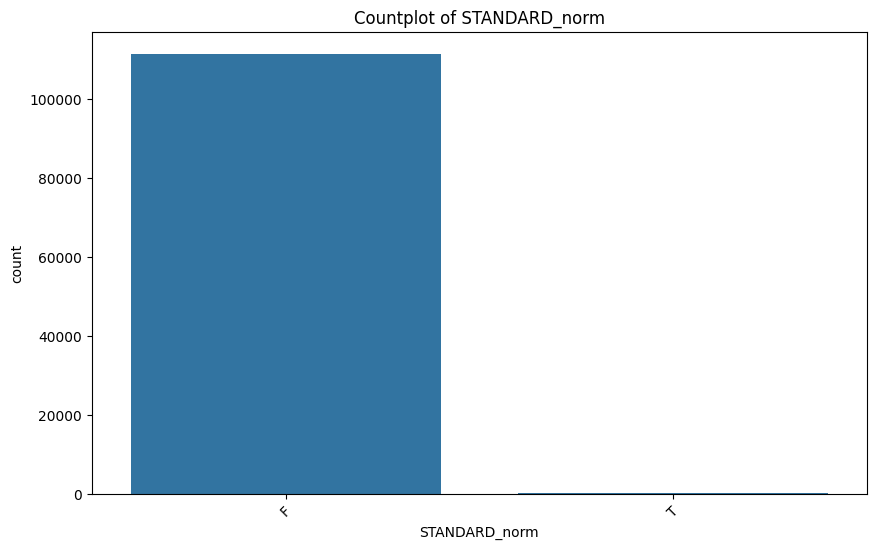

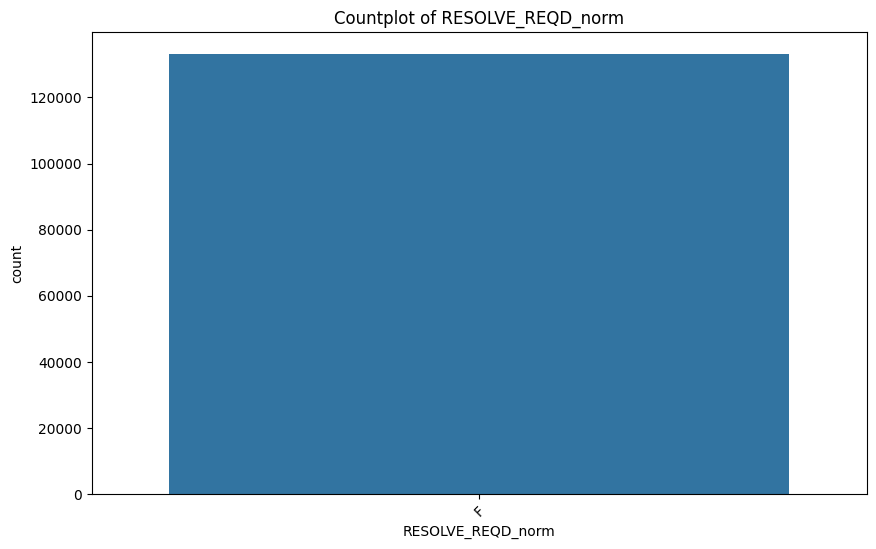

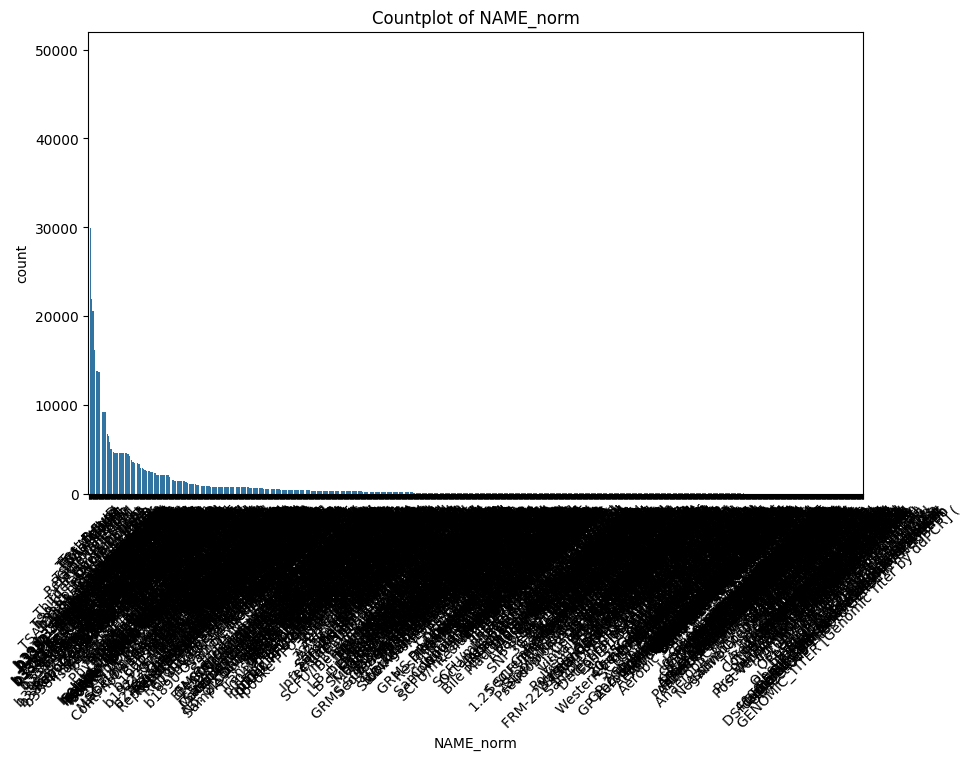

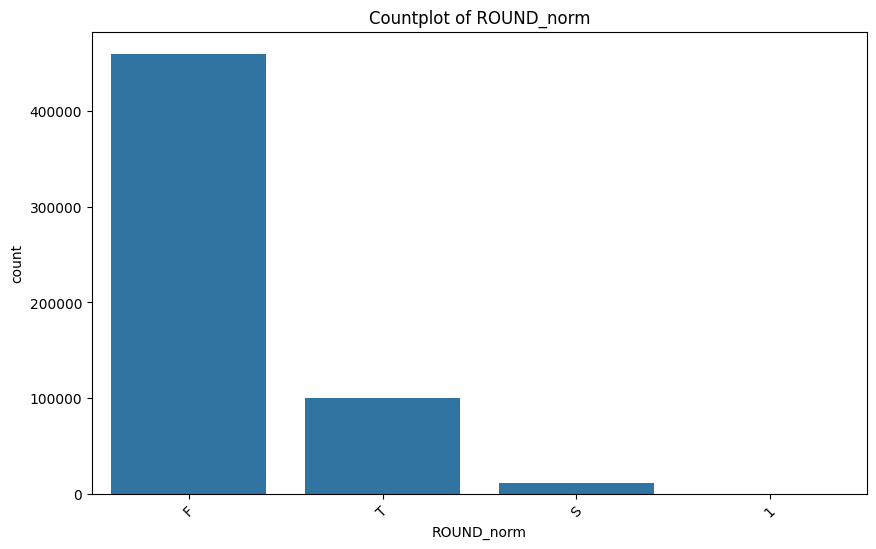

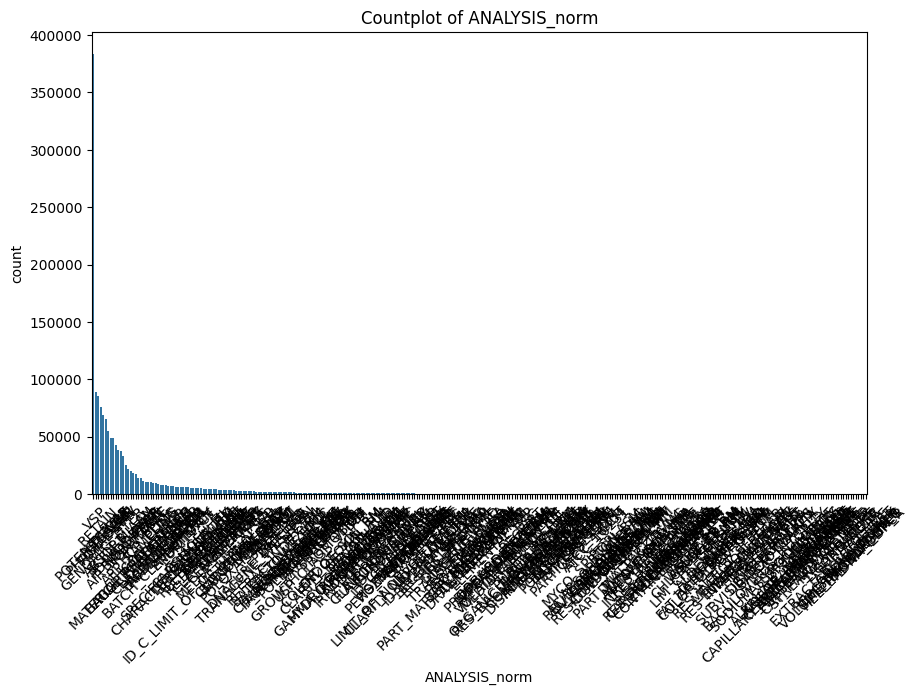

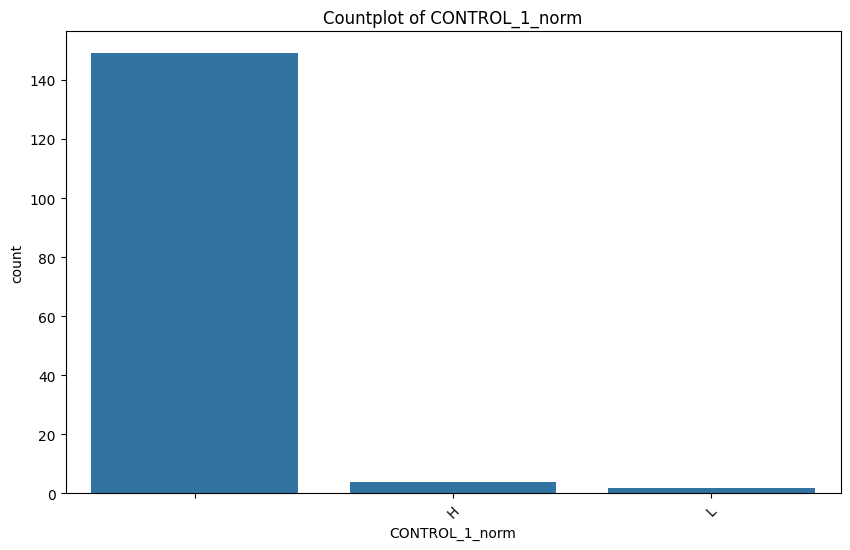

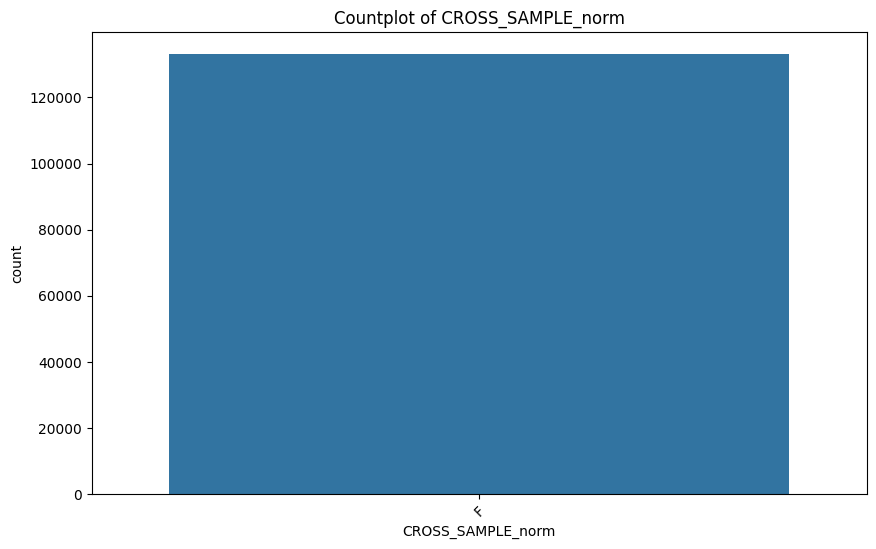

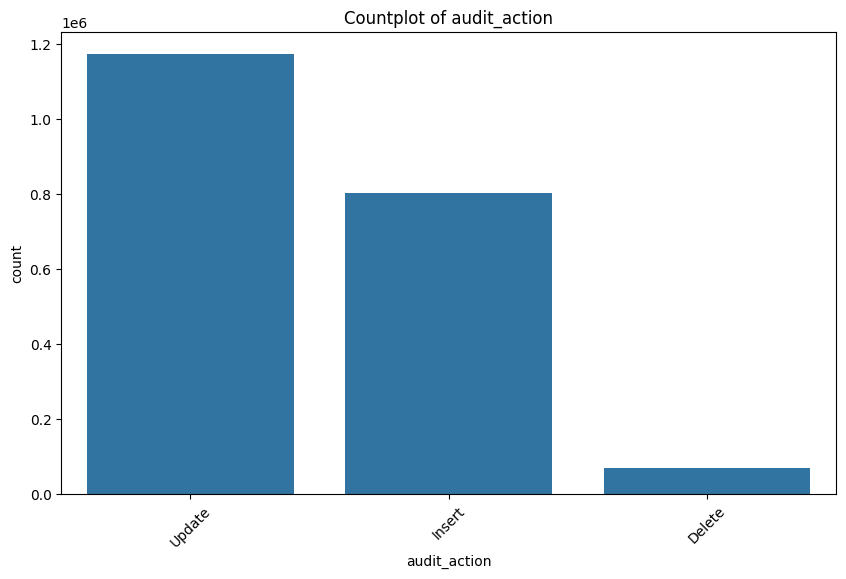

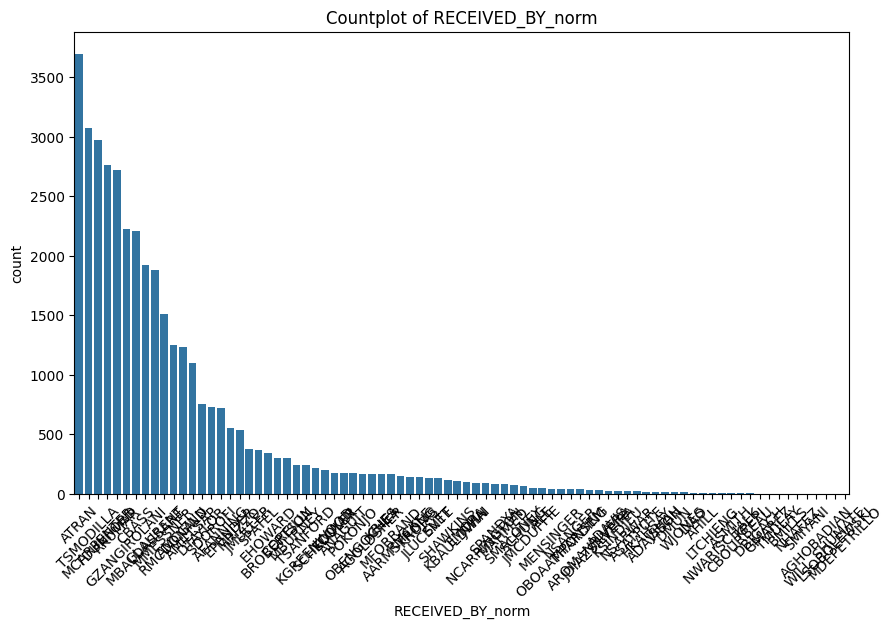

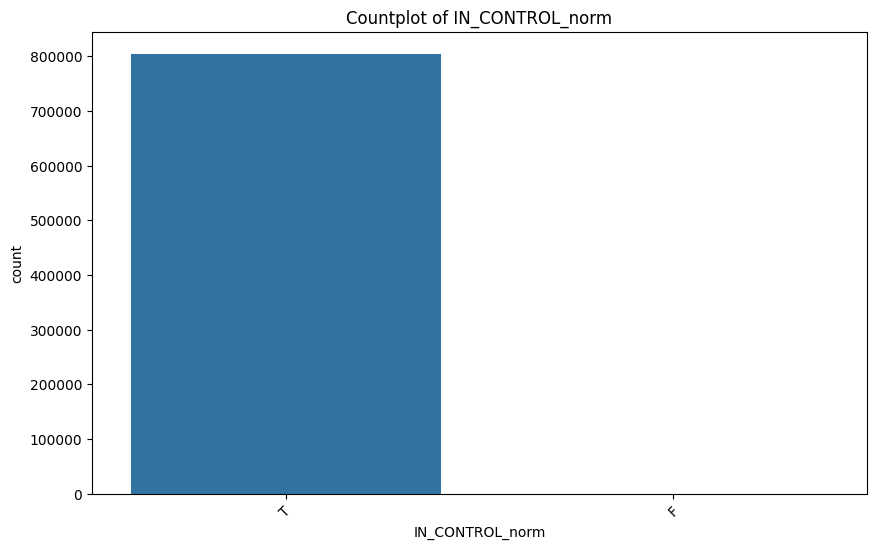

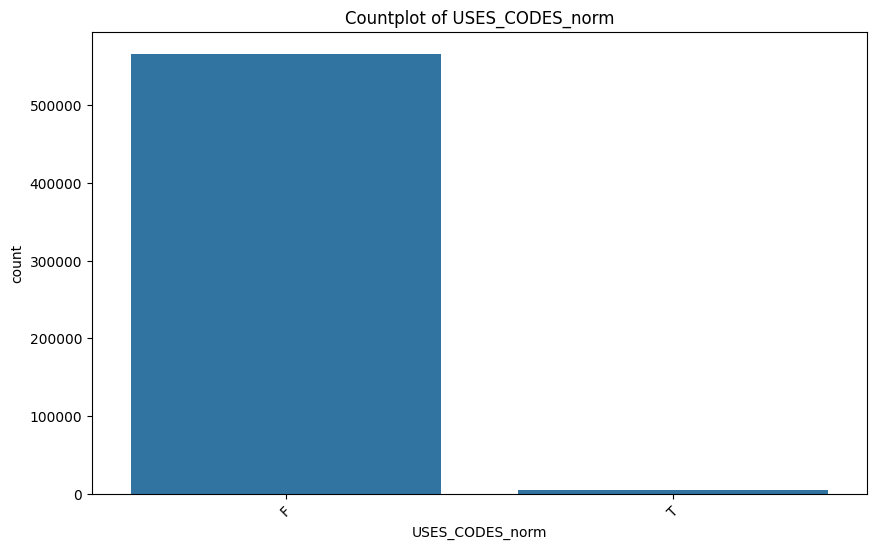

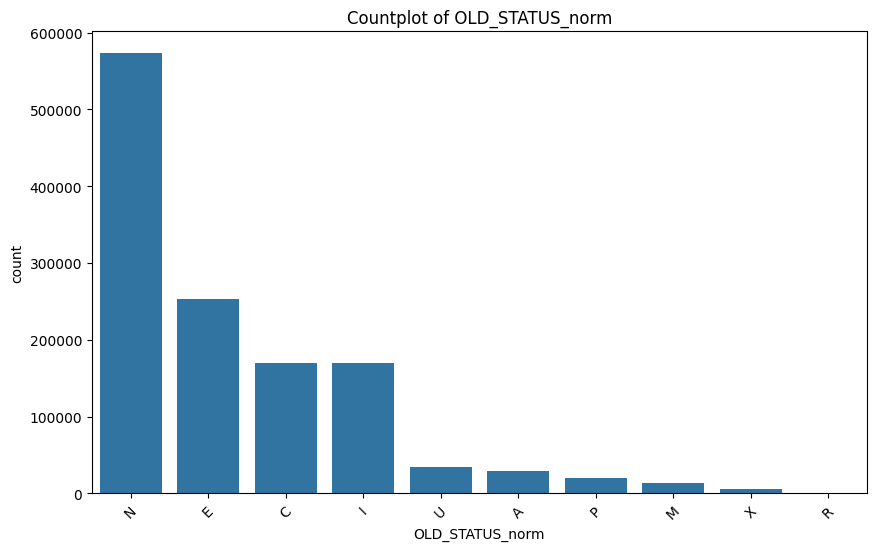

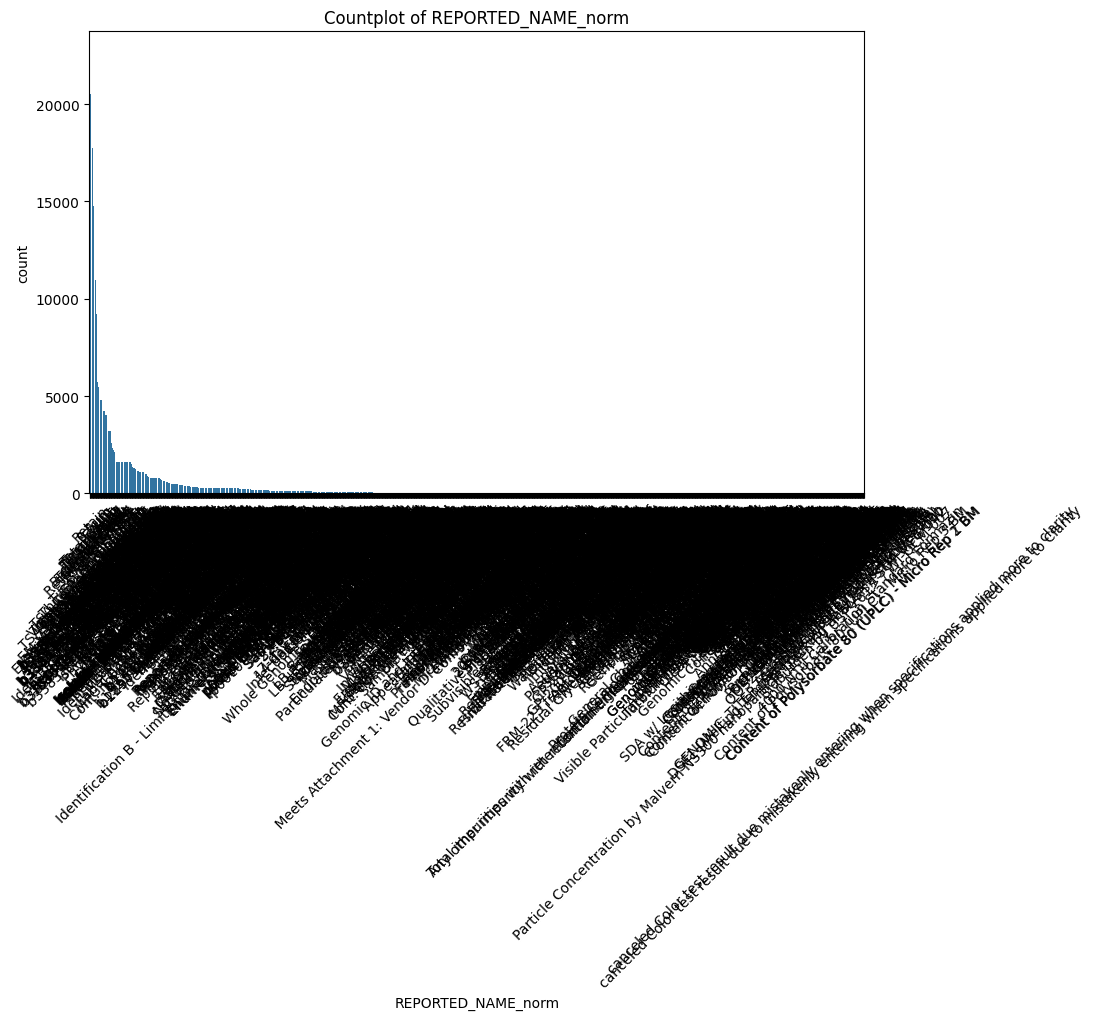

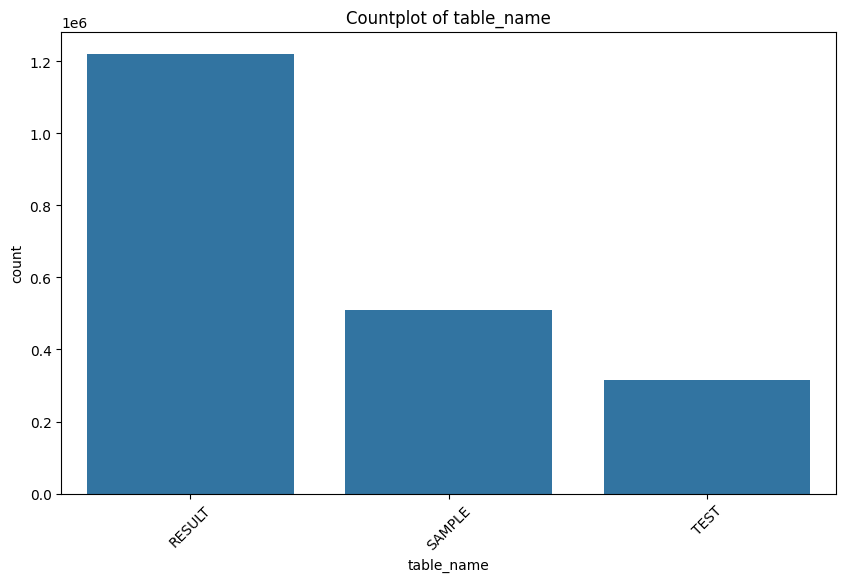

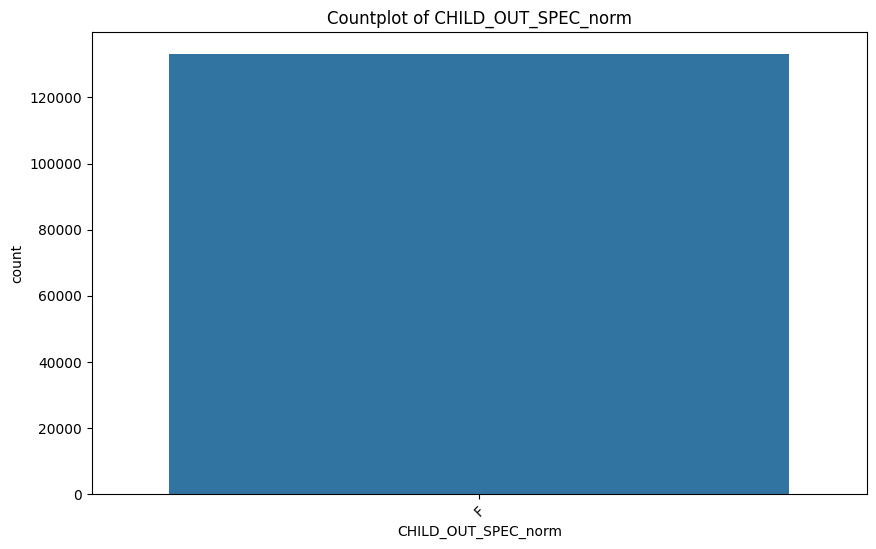

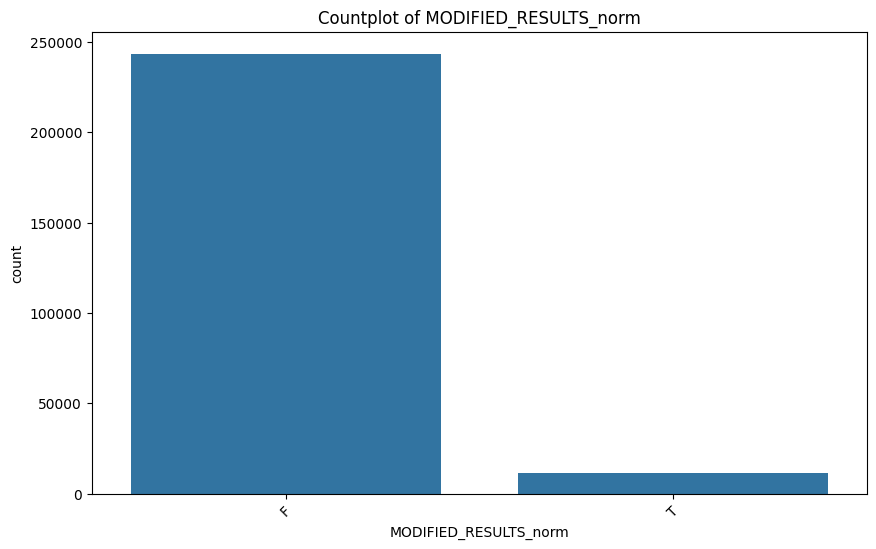

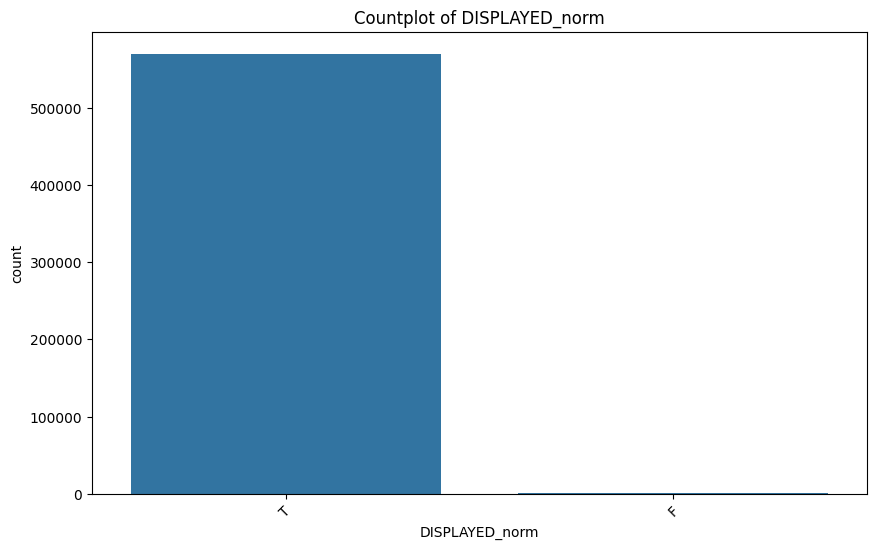

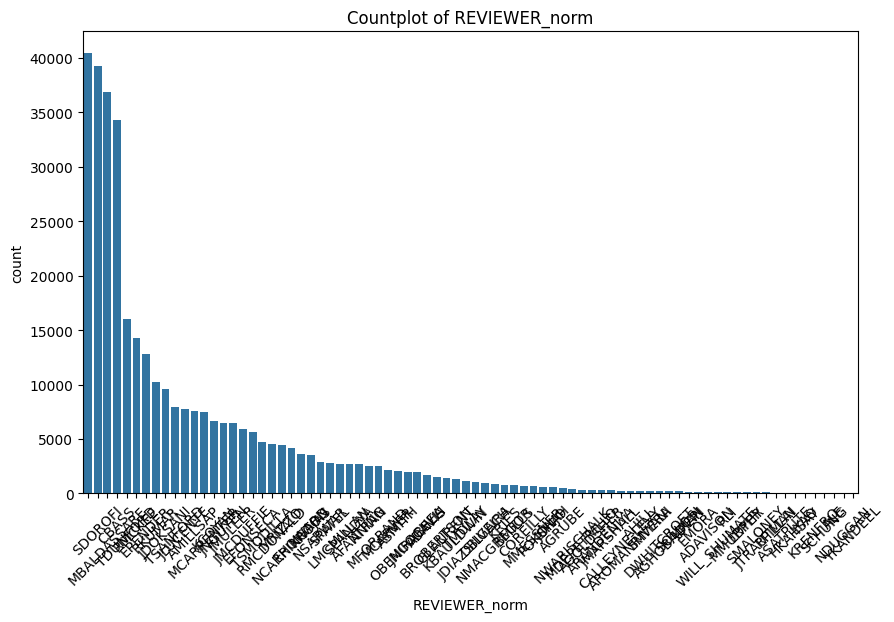

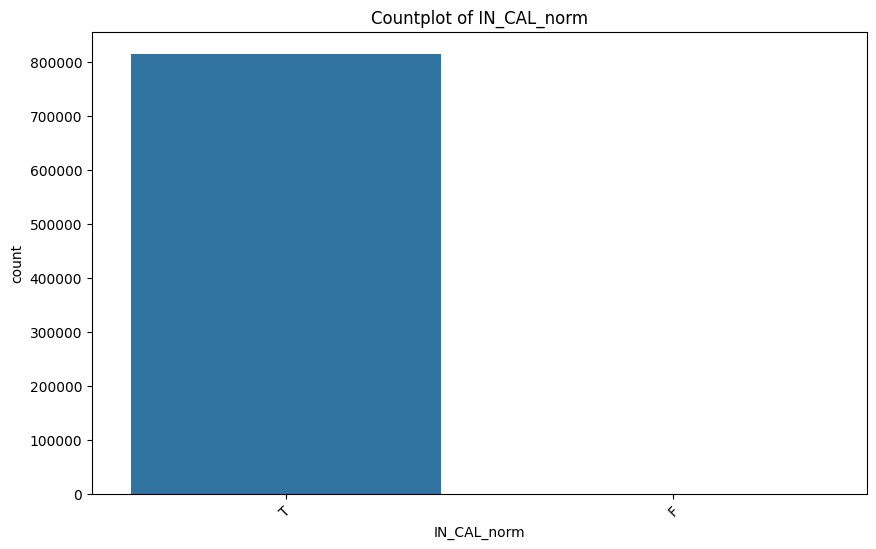

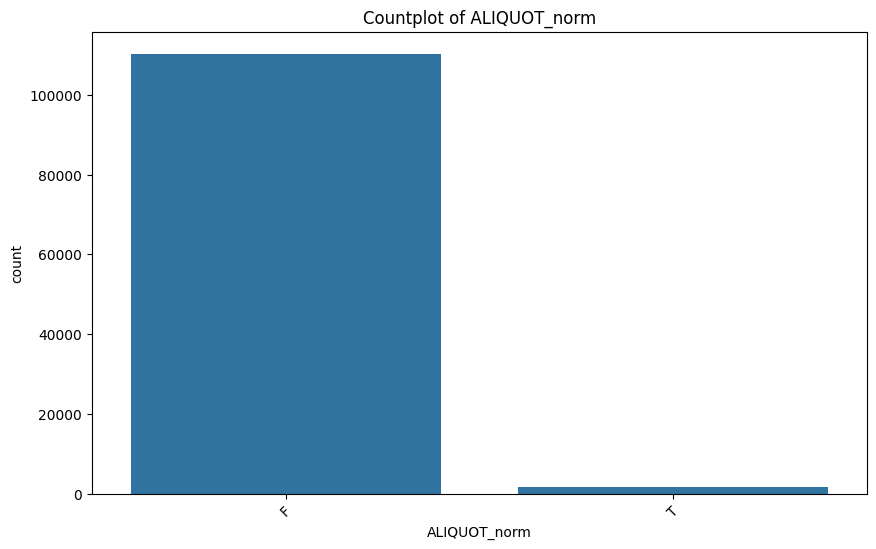

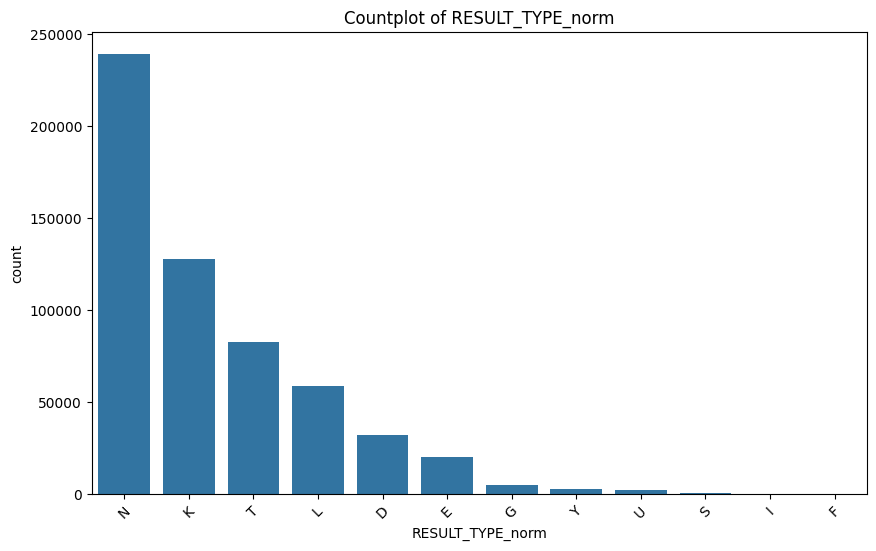

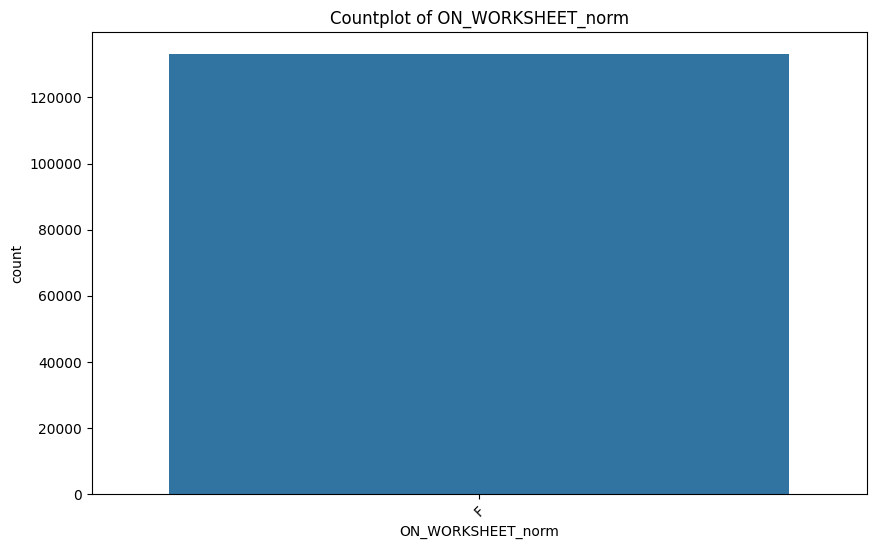

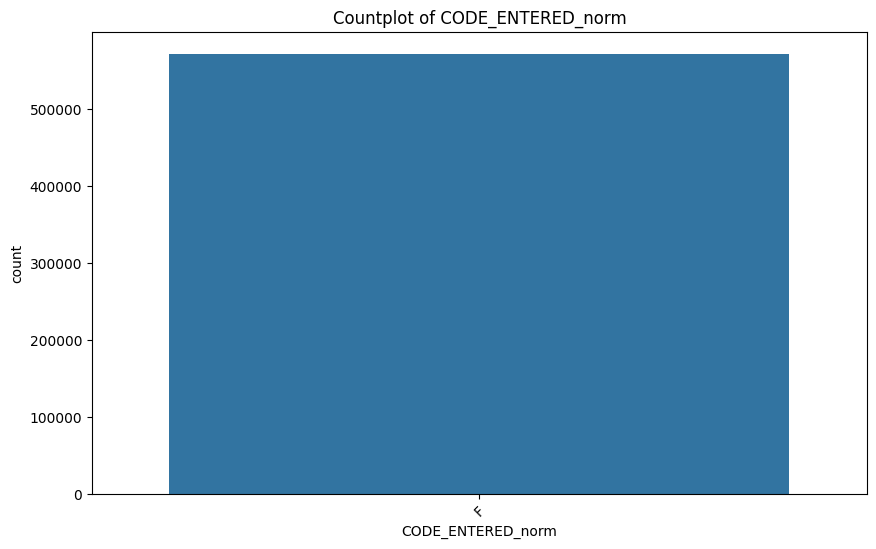

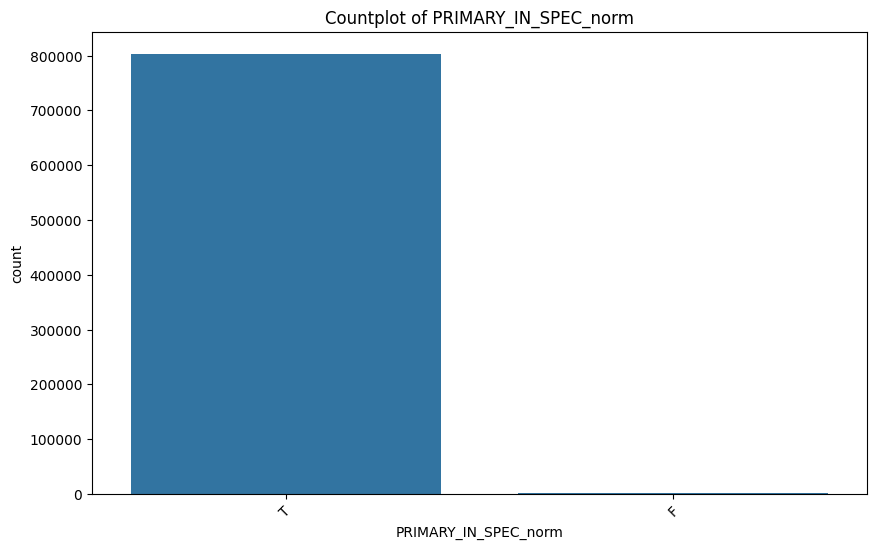

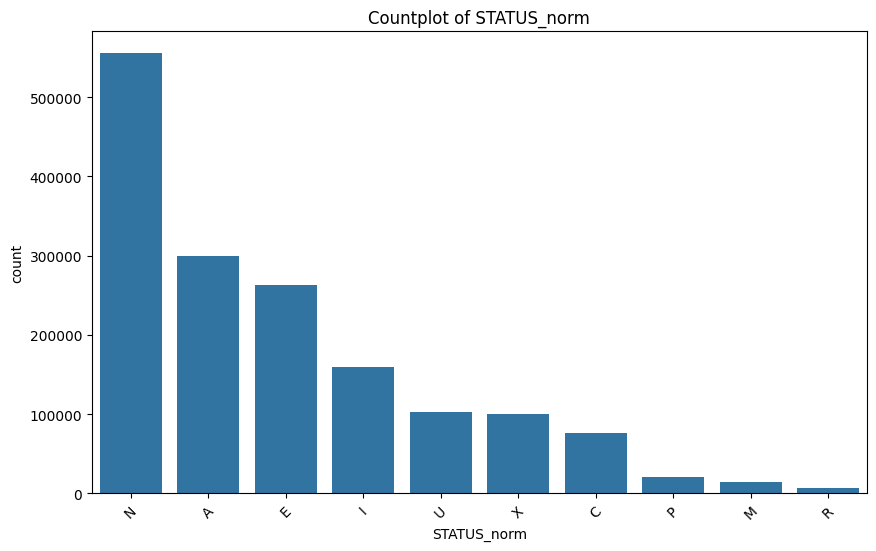

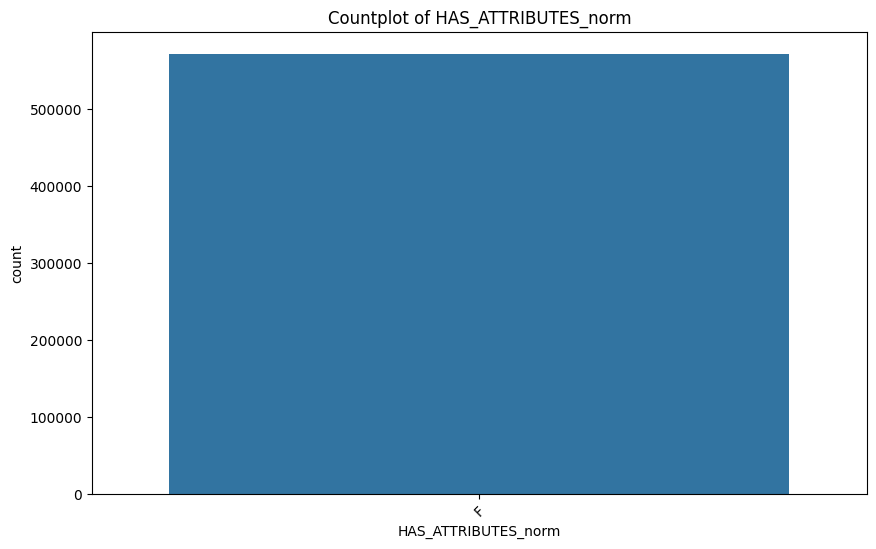

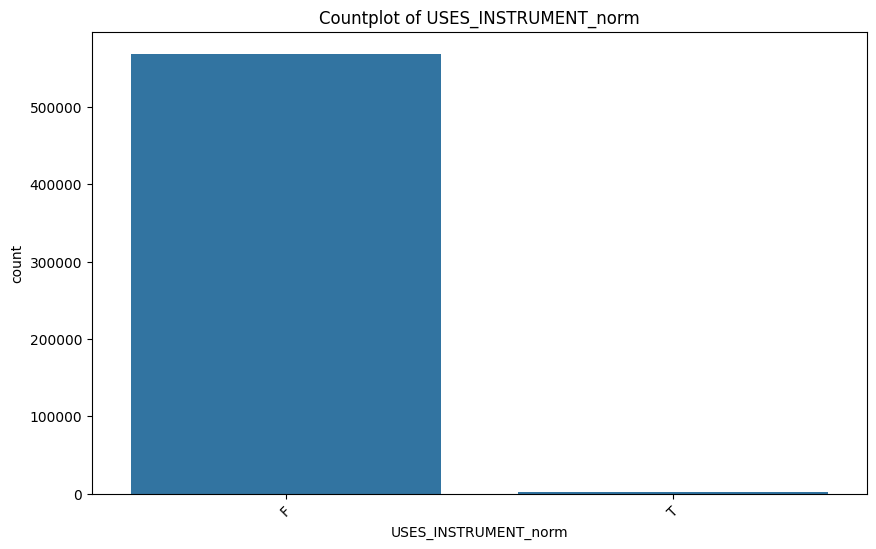

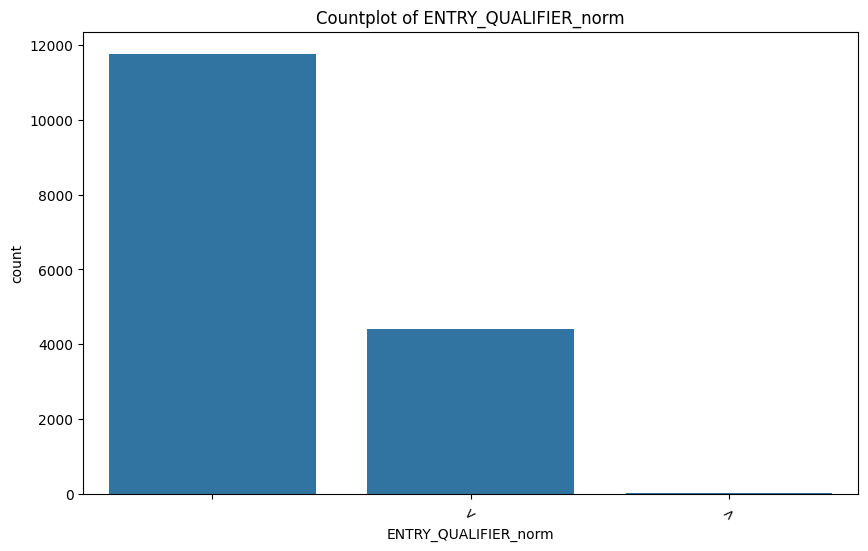

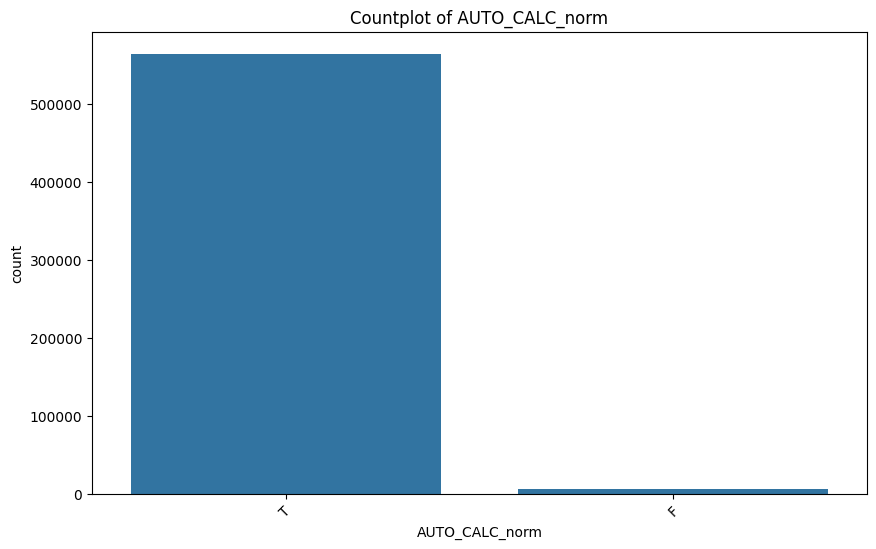

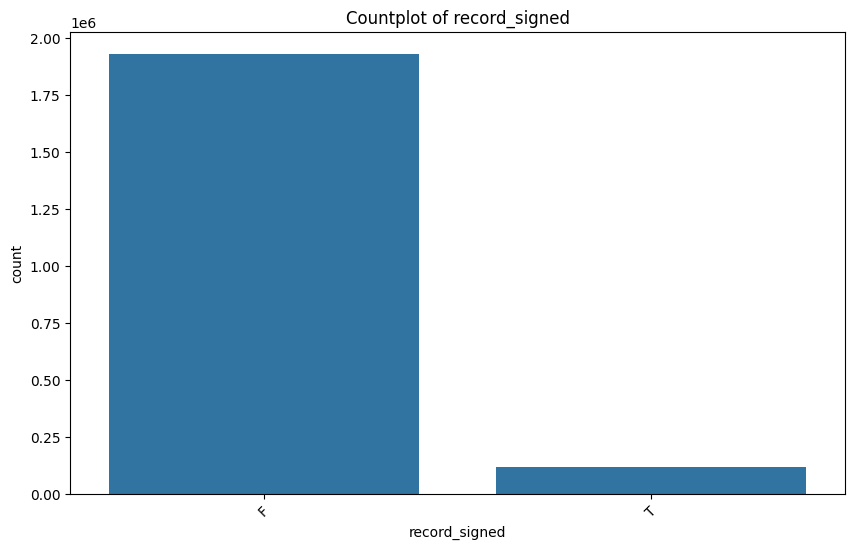

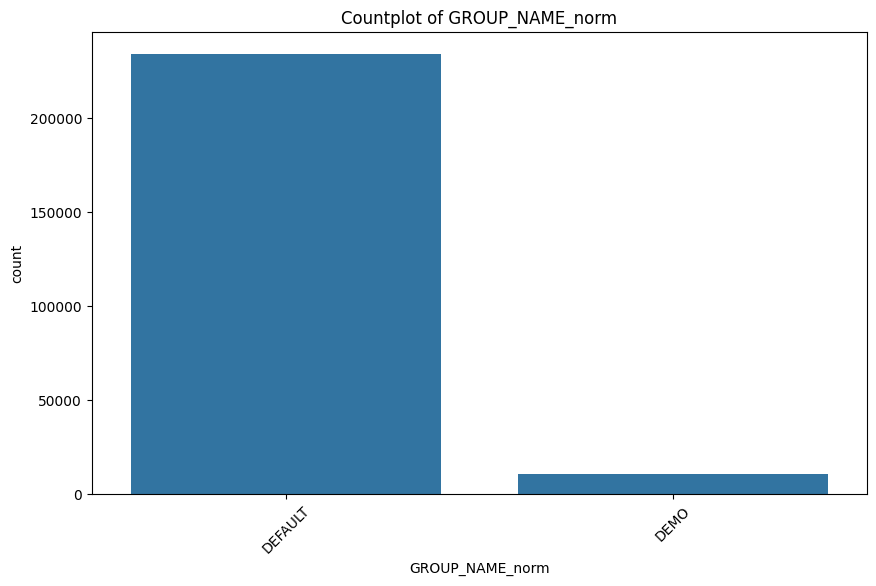

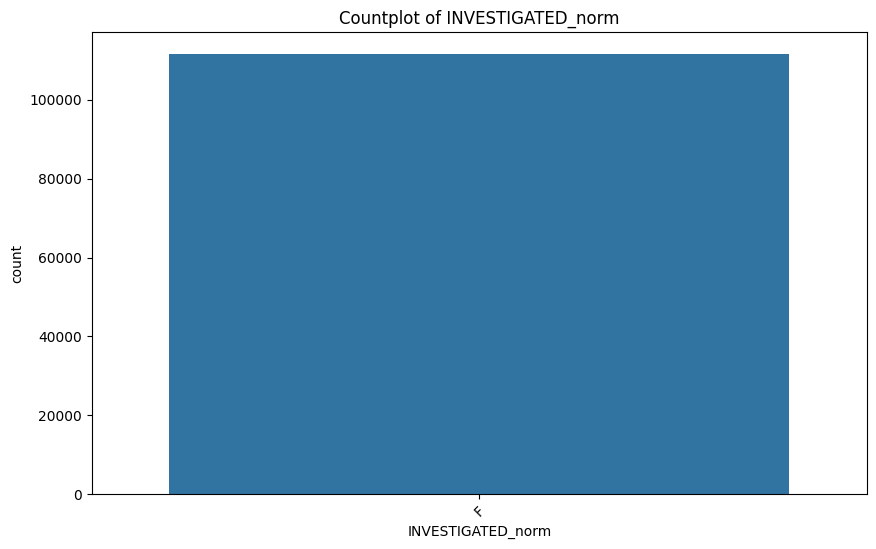

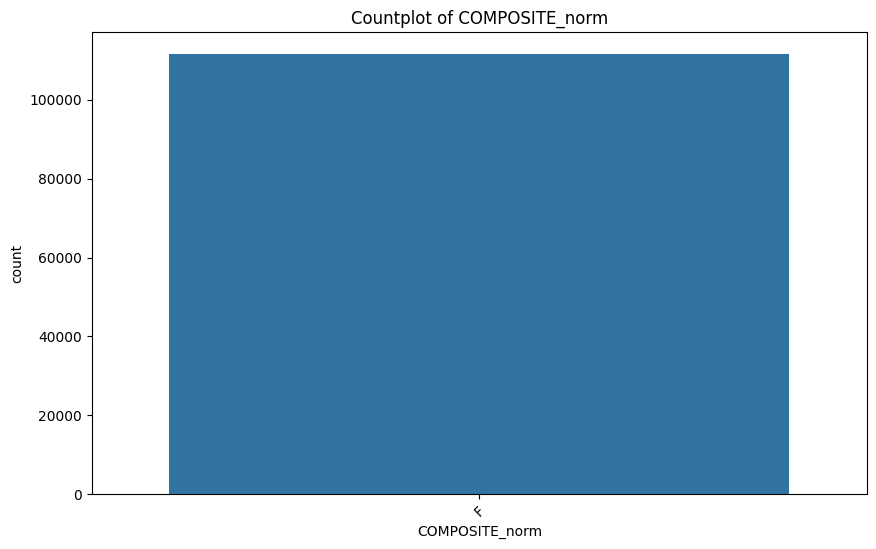

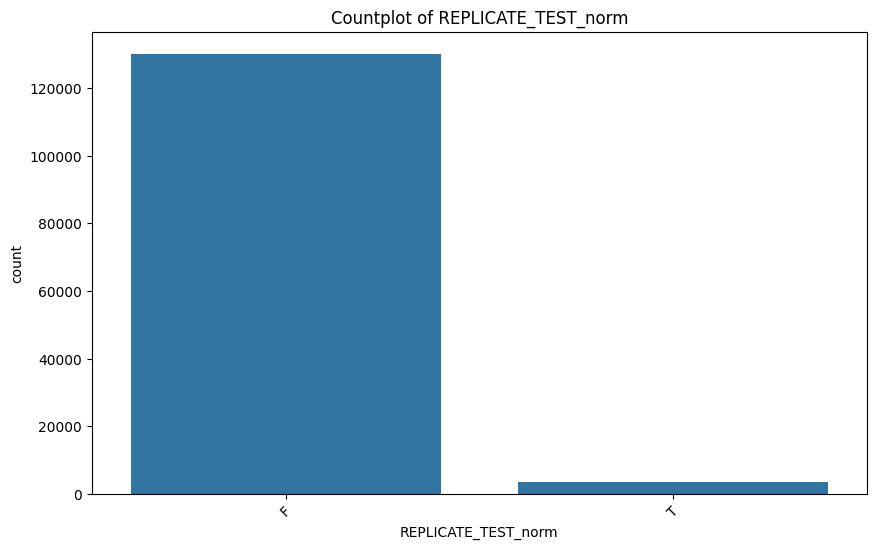

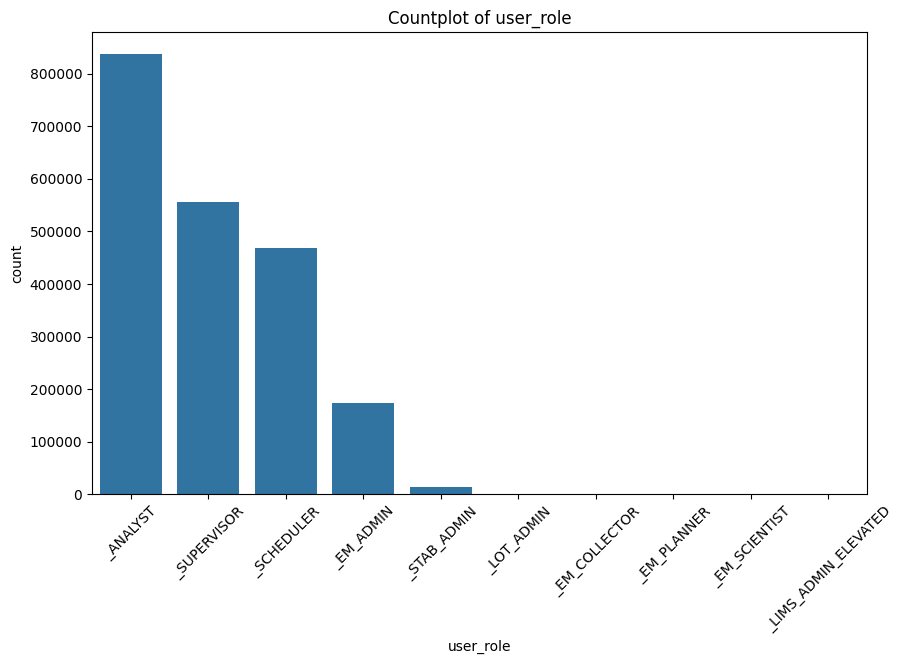

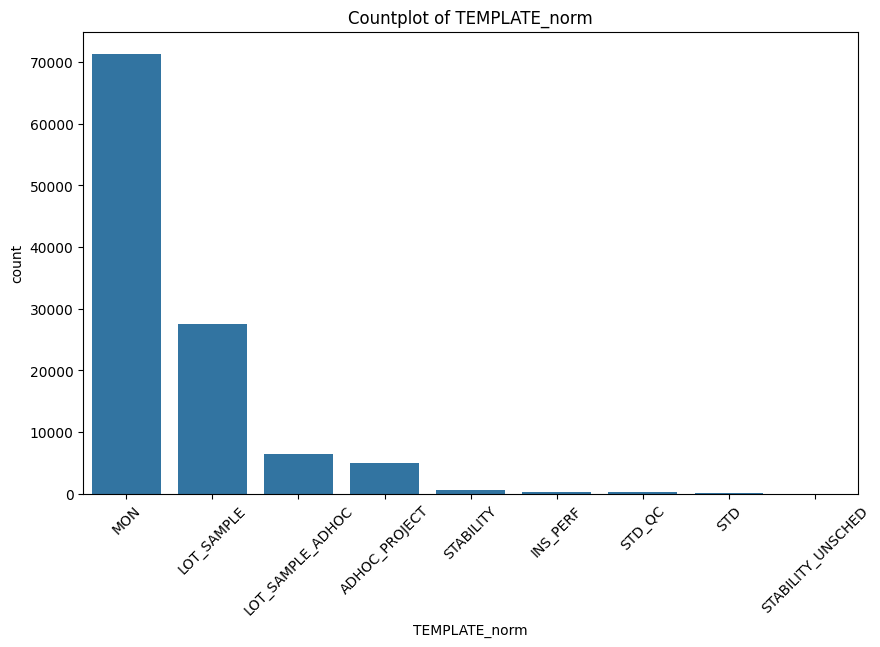

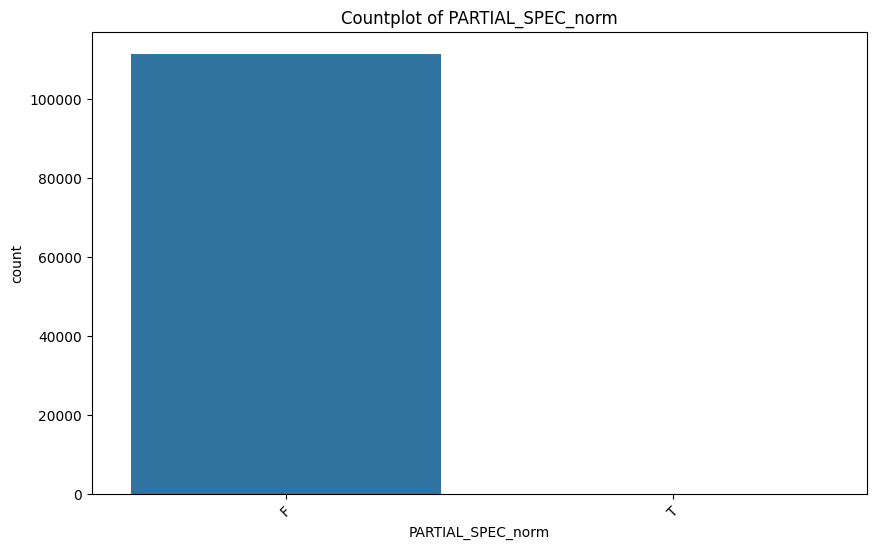

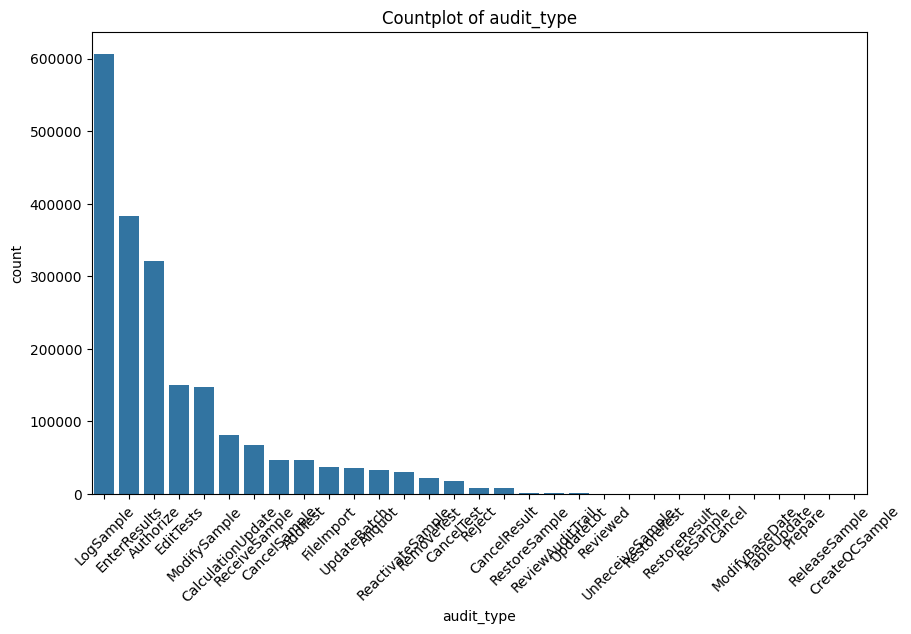

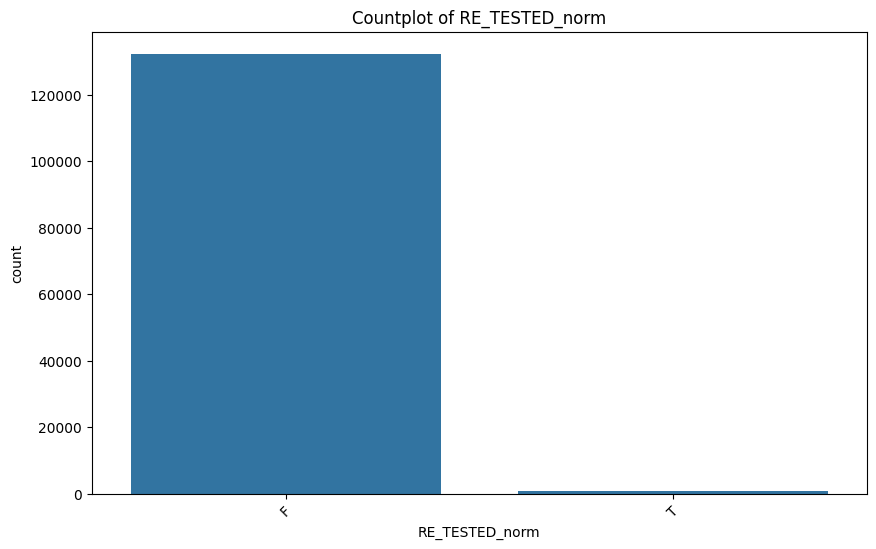

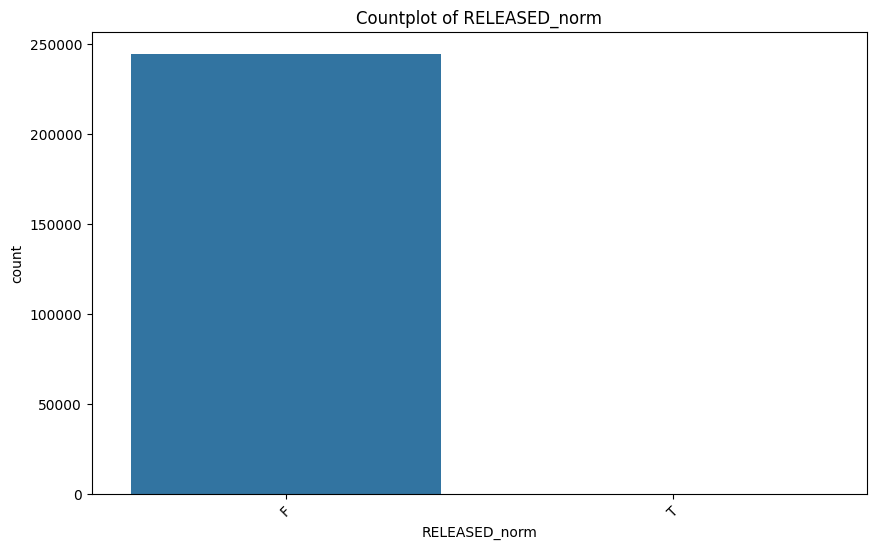

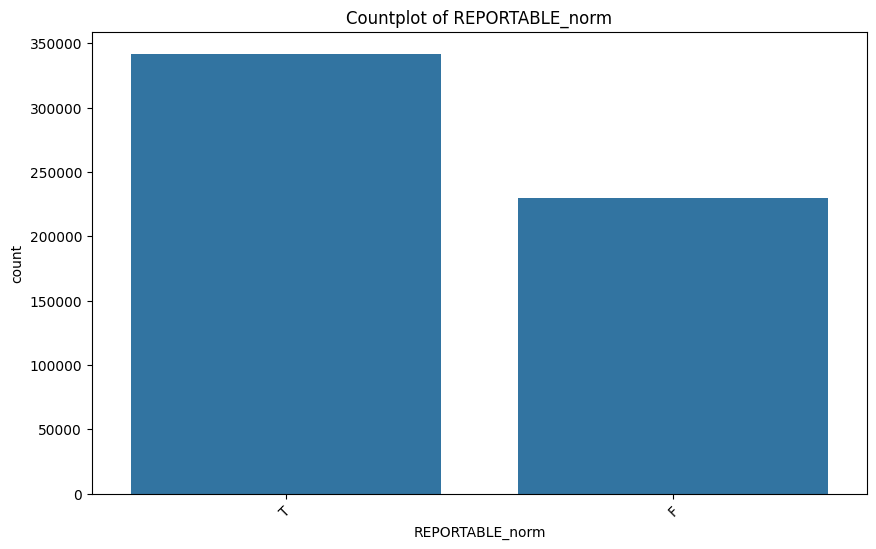

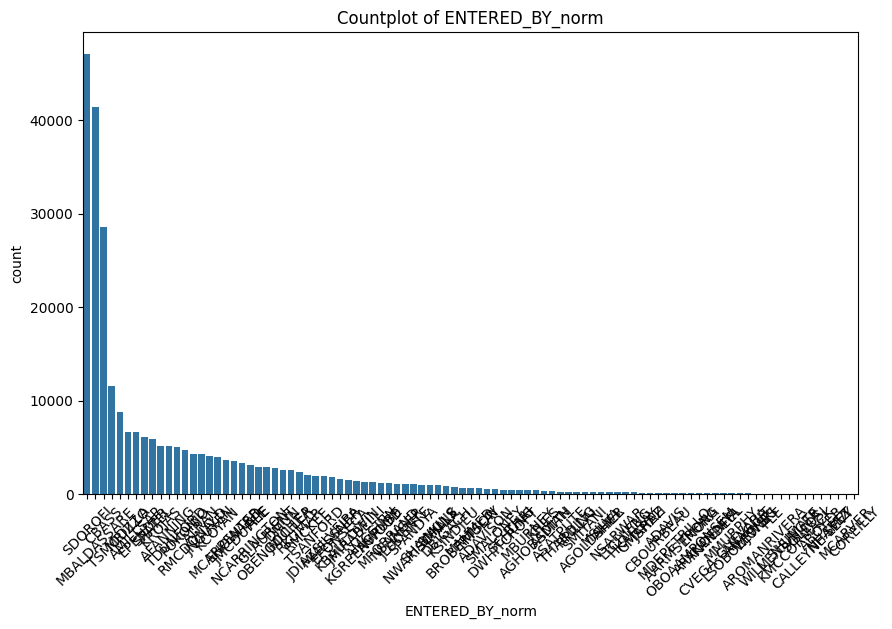

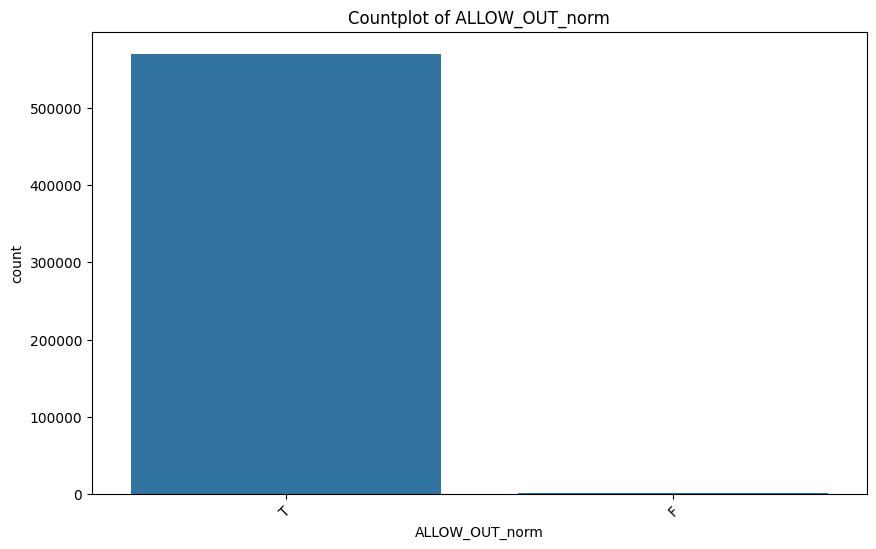

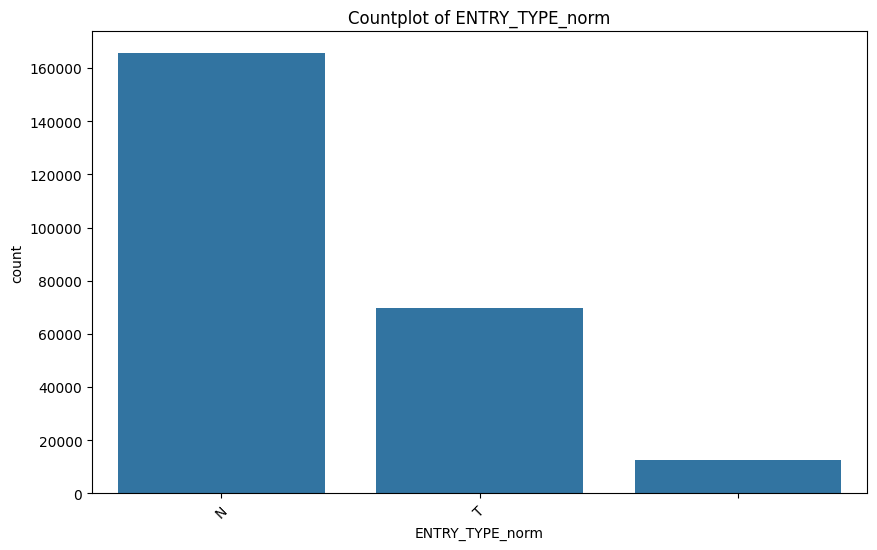

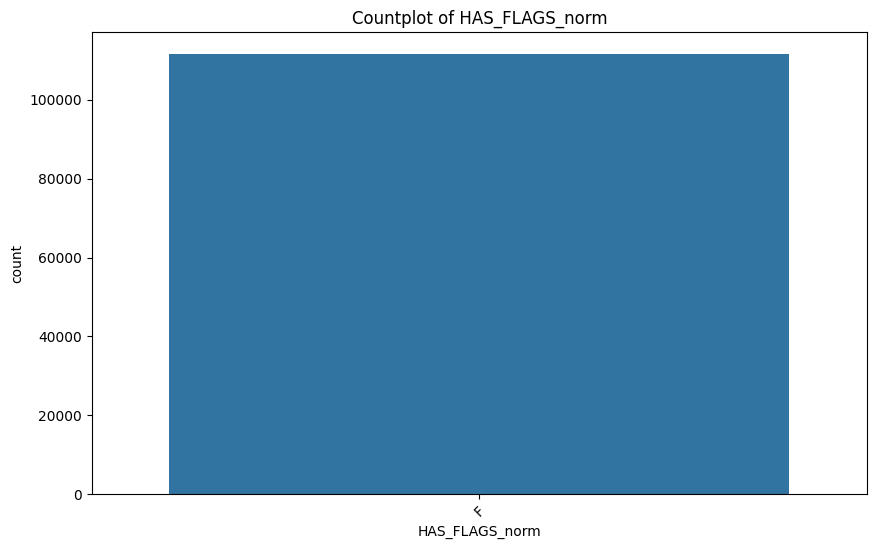

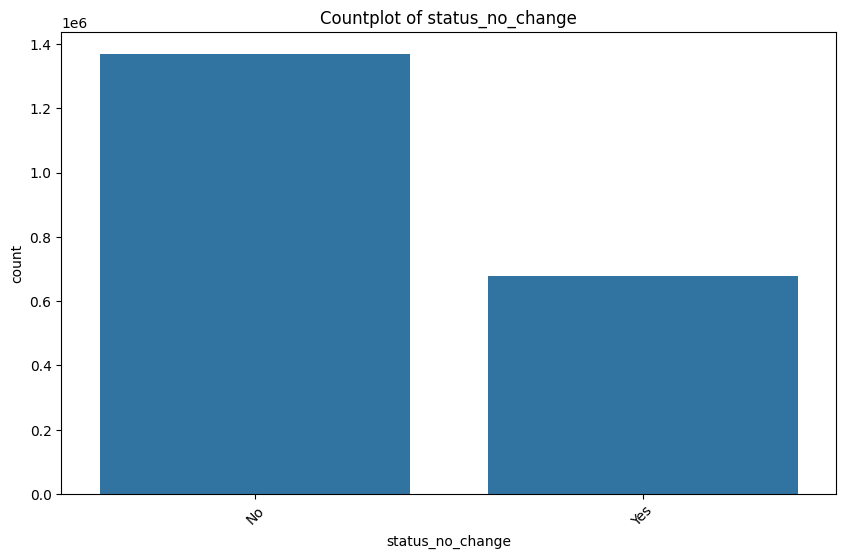

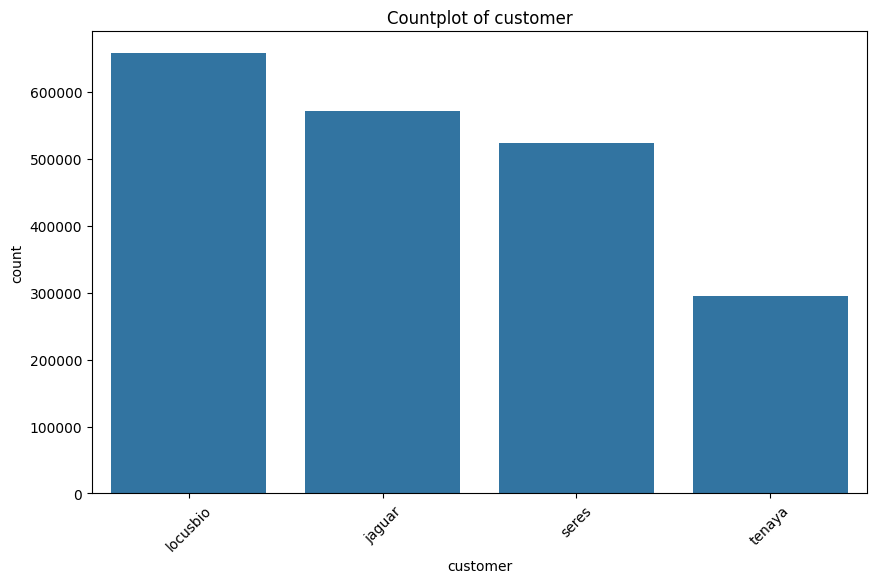

In [17]:
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    plt.figure(figsize=(10, 6))
    sns.countplot(x=col, data=df, order=df[col].value_counts().index)
    plt.title(f"Countplot of {col}")
    plt.xticks(rotation=45)
    plt.show()

KeyError: 'your_target_column'

<Figure size 1200x600 with 0 Axes>

In [25]:
df['reason'].value_counts()

reason
No reason specified                                                                                                                            1478443
Initial result entry                                                                                                                            233656
Updates by routine ET_SAMPLE_LOGGED_MON                                                                                                          73870
Initial Calculation                                                                                                                              48513
Auto Adding Sample to EM Plan via subroutine ET_SAMPLE_LOGGED_MON_AUTO_PLAN                                                                      36450
                                                                                                                                                ...   
Result needed to be reported as N/A (not zero) as it is outside countable range. Need t

In [47]:
df['contains_error'] = df['reason'].str.contains('error', case=False)
df['typo'] = df['reason'].str.contains('typographical', case=False)
df['Initial'] = df['reason'].str.contains('initial', case=False)
df['Unused'] = df['reason'].str.contains('Unused', case=False)
df['calculation'] = df['reason'].str.contains('calculation', case=False)


In [42]:
df['Unused'].value_counts()

Unused
False    2046113
Name: count, dtype: int64

In [48]:
df[['calculation','customer']].value_counts()

calculation  customer
False        locusbio    592739
             jaguar      542691
             seres       516356
             tenaya      295438
True         locusbio     64578
             jaguar       27925
             seres         6348
             tenaya          38
Name: count, dtype: int64

In [49]:
(df['contains_error'] & df['Initial']).sum()

9894